# Исследование данных инцидентов метрополитена
Целью данного исследования является исследование сведений об инцидентах в Московском метрополитене с целью поиска закономерностей и аномалий.

Состав исследования:


1.   Загрузка модулей, данных и первичный анализ качества данных
2.   Анализ данных
3.   Корреляционный анализ
4.   Выводы

## Загрузка модулей, данных и первичный анализ

In [58]:
pip install phik -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
# from google.colab import drive
# drive.mount('/content/drive')

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik
import textwrap
from statsmodels.tsa.seasonal import seasonal_decompose

In [61]:
data = pd.read_excel("../downloads/нарушения ММ.xlsx")
display(data.tail(5))

,Начало случая,Окончание случая,"Перерыв в движении, мин",id станции,Станционный путь,Перегон,Кол-во опоздавших поездов,Кол-во минут опоздания,Кол-во полных отмен,Кол-во участковых отмен,Кол-во внеплановых высадок пассажиров,Линия,Ответственная служба,Тип нарушения,Причины возникновения,Наименование устройства,Наименование детали устройства,Общая причина возникновения
102146,1975-12-25 23:26:00,2023-12-25 23:27:00,0,81.0,NaN,NaN,0,0,0,0,0,Кольцевая,ЭС,Падение пассажира на эскалаторе без травм,Падение пассажира на эскалаторе без травм,Эскалатор,Вогнутый участок,Действия пассажиров
102147,1975-12-25 23:44:00,2023-12-25 23:51:00,0,298.0,NaN,NaN,0,0,0,0,0,Большая кольцевая,ЭС,Остановка эскалатора ручкой СТОП пассажирами,Остановка эскалатора ручкой СТОП пассажирами,Эскалатор,NaN,Действия пассажиров
102148,1975-12-25 23:45:00,2023-12-25 23:46:00,0,254.0,NaN,NaN,0,0,0,0,0,Серпуховско-тимирязевская,ЭС,Падение пассажира на эскалаторе без травм,Падение пассажира на эскалаторе без травм,Эскалатор,Середина наклона,Действия пассажиров
102149,1975-12-25 23:53:00,2023-12-25 23:56:00,0,275.0,NaN,NaN,0,0,0,0,0,Таганско-краснопресненская,ЭС,Остановка эскалатора ручкой СТОП из-за угрозы ...,Остановка эскалатора ручкой СТОП из-за угрозы ...,Эскалатор,NaN,Действия пассажиров
102150,1975-12-25 23:53:00,2023-12-25 23:54:00,0,90.0,NaN,NaN,0,0,0,0,0,Калининская,ЭС,Остановка эскалатора ручкой СТОП из-за угрозы ...,Остановка эскалатора ручкой СТОП из-за угрозы ...,Эскалатор,NaN,Действия пассажиров


Сразу можно подметить, что у инцидентов слишком большой разброс начала и окончания по годам

In [62]:
data.describe()

,Начало случая,Окончание случая,"Перерыв в движении, мин",id станции,Кол-во опоздавших поездов,Кол-во минут опоздания,Кол-во полных отмен,Кол-во участковых отмен,Кол-во внеплановых высадок пассажиров
count,102151,102151,102151.000000,98111.000000,102151.000000,102151.000000,102151.000000,102151.000000,102151.000000
mean,1975-01-29 02:15:05.121829408,2022-08-18 07:35:31.876692224,0.048898,133.940027,0.002379,0.046255,0.004944,0.145500,0.080792
min,1974-01-01 00:00:00,1974-01-01 08:31:00,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1974-07-30 08:55:00,2022-07-27 10:10:00,0.000000,67.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1975-02-15 10:18:00,2023-02-15 13:24:00,0.000000,107.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1975-08-04 20:30:00,2023-08-04 23:53:30,0.000000,215.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1975-12-25 23:53:00,2023-12-26 02:39:00,330.000000,307.000000,2.000000,320.000000,15.000000,202.000000,202.000000
std,NaN,NaN,1.655264,88.301054,0.049907,1.508340,0.111875,1.176239,0.837965


In [63]:
print('Duplicates:', data.duplicated().sum())
print('Missing values:', '\n', data.isna().sum())

Duplicates: 609
Missing values: 
 Начало случая                                0
Окончание случая                             0
Перерыв в движении, мин                      0
id станции                                4040
Станционный путь                         88634
Перегон                                  98111
Кол-во опоздавших поездов                    0
Кол-во минут опоздания                       0
Кол-во полных отмен                          0
Кол-во участковых отмен                      0
Кол-во внеплановых высадок пассажиров        0
Линия                                        0
Ответственная служба                         0
Тип нарушения                                0
Причины возникновения                        0
Наименование устройства                    150
Наименование детали устройства           64170
Общая причина возникновения                  0
dtype: int64


Дубликатов немного, можно удалить. В сведениях о Станционном пути, перегоне и Наименовании детали устройства крайне много пропусков

In [64]:
data = data.drop_duplicates()
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 101542 entries, 0 to 102150
Data columns (total 18 columns):
 #   Column                                 Non-Null Count   Dtype         
---  ------                                 --------------   -----         
 0   Начало случая                          101542 non-null  datetime64[ns]
 1   Окончание случая                       101542 non-null  datetime64[ns]
 2   Перерыв в движении, мин                101542 non-null  int64         
 3   id станции                             97503 non-null   float64       
 4   Станционный путь                       13507 non-null   object        
 5   Перегон                                4039 non-null    object        
 6   Кол-во опоздавших поездов              101542 non-null  int64         
 7   Кол-во минут опоздания                 101542 non-null  int64         
 8   Кол-во полных отмен                    101542 non-null  int64         
 9   Кол-во участковых отмен                101542 non-nul

In [65]:
for i in data.columns:
    print(i, ':', data[i].nunique())

Начало случая : 92304
Окончание случая : 94616
Перерыв в движении, мин : 48
id станции : 266
Станционный путь : 7
Перегон : 480
Кол-во опоздавших поездов : 3
Кол-во минут опоздания : 49
Кол-во полных отмен : 9
Кол-во участковых отмен : 44
Кол-во внеплановых высадок пассажиров : 28
Линия : 14
Ответственная служба : 9
Тип нарушения : 76
Причины возникновения : 205
Наименование устройства : 730
Наименование детали устройства : 2309
Общая причина возникновения : 6


In [66]:
service_mapping = {
    'ЭС': 'Эскалаторная служба',
    'Б': 'Служба безопасности',
    'ДИТС': 'Дирекция информационных технологий и систем связи',
    'П': 'Служба пути',
    'Т': 'Служба подвижного состава',
    'Ш': 'Служба сигнализации, централизации и блокировки',
    'Э': 'Служба электроснабжения',
    'ЭМ': 'Электромеханическая служба',
    'СПО': 'Служба пассажирских обустройств'
}

data['Ответственная служба'] = data['Ответственная служба'].replace(service_mapping)

## Работа с некорректными датами

Длительность инцидентов в 40+ лет выглядит подозрительно, поэтому стоит попробовать исследовать и в случае допустимости исправить данные

In [67]:
print(data['Начало случая'].dt.year.value_counts().sort_index())
print(data['Окончание случая'].dt.year.value_counts().sort_index())

Начало случая
1974    45325
1975    56217
Name: count, dtype: int64
Окончание случая
1974      955
2022    44352
2023    56235
Name: count, dtype: int64


In [68]:
duration = data['Окончание случая'] - data['Начало случая']
print(duration.min())
print(duration.max())
print(duration.mean())
duration.describe(percentiles=[
    .01, .05, .25, .5, .75, .9, .95, .99, .999
])

0 days 00:00:00
17979 days 19:09:00
17367 days 05:45:56.750468096


count                           101542
mean     17367 days 05:45:56.750468096
std       1692 days 05:39:51.718498784
min                    0 days 00:00:00
1%                 17532 days 00:00:00
5%                 17532 days 00:01:00
25%                17532 days 00:01:00
50%                17532 days 00:02:00
75%                17532 days 00:08:00
90%                17532 days 00:48:00
95%                17532 days 01:51:00
99%                17532 days 23:49:00
99.9%       17552 days 10:57:27.540000
max                17979 days 19:09:00
dtype: object

In [69]:
mask = data['Начало случая'].notna() & data['Окончание случая'].notna()

same_calendar = (
    (data.loc[mask, 'Начало случая'].dt.month == data.loc[mask, 'Окончание случая'].dt.month) &
    (data.loc[mask, 'Начало случая'].dt.day   == data.loc[mask, 'Окончание случая'].dt.day) &
    (data.loc[mask, 'Начало случая'].dt.hour  == data.loc[mask, 'Окончание случая'].dt.hour)
)
print(same_calendar.mean())

0.8211183549664178


Хотя говорить о точном восстановлении года на 100% нельзя, с учетом того, что для большинства инцидентов совпадают месяц, день и час, допущу что произошла ошибка при выгрузке годов начала инцидентов. Доля совпадений этих частей дат не 100% вероятно потому что имеется ряд инцидентов, которые начались в одном часу, а закончились в другом.

In [70]:
same_year = data[
    data['Начало случая'].dt.year ==
    data['Окончание случая'].dt.year
]

same_year[['Начало случая', 'Окончание случая']].head()
duration = same_year['Окончание случая'] - same_year['Начало случая']

duration.describe(percentiles=[0.5, 0.9, 0.95, 0.99])

count                          955
mean     0 days 03:26:39.706806282
std      0 days 16:13:18.961988544
min                0 days 00:00:00
50%                0 days 00:44:00
90%                0 days 04:33:12
95%      0 days 17:20:05.999999999
99%                1 days 13:54:12
max               13 days 14:02:00
dtype: object

Часть инцидентов имеют 1974 год и в начале и в конце инцидента. Вероятно являются реальными, тестовыми, или ошибочными с годом и в начале и в окончании. Установить истину в данном случае не представляется возможным.

In [71]:
_1974_end_year = data[data['Окончание случая'].dt.year == 1974]
_1974_end_year = len(_1974_end_year) / len(data)

print(f"Доля данных, где год окончания инцидента 1974: {_1974_end_year:.2%}")

Доля данных, где год окончания инцидента 1974: 0.94%


Записи с годом окончания 1974 (0.94% выборки) исключены из дальнейшего анализа, поскольку корректность их дат не удалось однозначно установить, а их доля несущественна для результатов исследования.

In [72]:
# Удаляем записи, где год окончания = 1974
data = data[data['Окончание случая'].dt.year != 1974].copy()

# Заменяем год начала на год окончания
data['Начало случая'] = data.apply(
    lambda row: row['Начало случая'].replace(
        year=row['Окончание случая'].year
    ),
    axis=1
)

# Проверяем, сколько записей имеют начало позже окончания
invalid_mask = data['Начало случая'] > data['Окончание случая']

print(f'Количество записей с началом позже окончания: {invalid_mask.sum()}')

# Просмотр проблемных записей
data.loc[
    invalid_mask,
    ['Начало случая', 'Окончание случая']
]

Количество записей с началом позже окончания: 16


,Начало случая,Окончание случая
21709,2023-07-01 05:50:00,2023-01-10 03:33:00
29089,2023-08-27 19:58:00,2023-02-03 02:24:00
33123,2023-09-26 15:36:00,2023-01-20 14:24:00
37723,2023-11-04 15:04:00,2023-06-01 03:08:00
44183,2023-12-24 08:49:00,2023-01-19 03:16:00
44334,2023-12-25 09:47:00,2023-01-11 03:10:00
44340,2023-12-25 10:25:00,2023-03-03 04:26:00
44917,2023-12-29 11:43:00,2023-01-02 16:35:00
45296,2023-12-31 04:06:00,2023-01-02 05:00:00
45379,2023-12-31 15:14:00,2023-01-02 05:00:00


In [73]:
# Уменьшаем год начала на 1
data.loc[invalid_mask, 'Начало случая'] = (
    data.loc[invalid_mask, 'Начало случая']
    .apply(lambda dt: dt.replace(year=dt.year - 1))
)

# Контрольная проверка
print(f'Осталось записей с началом позже окончания: {invalid_mask.sum()}')

Осталось записей с началом позже окончания: 16


## Анализ данных

### Зависимость количества инцидентов от различных признаков

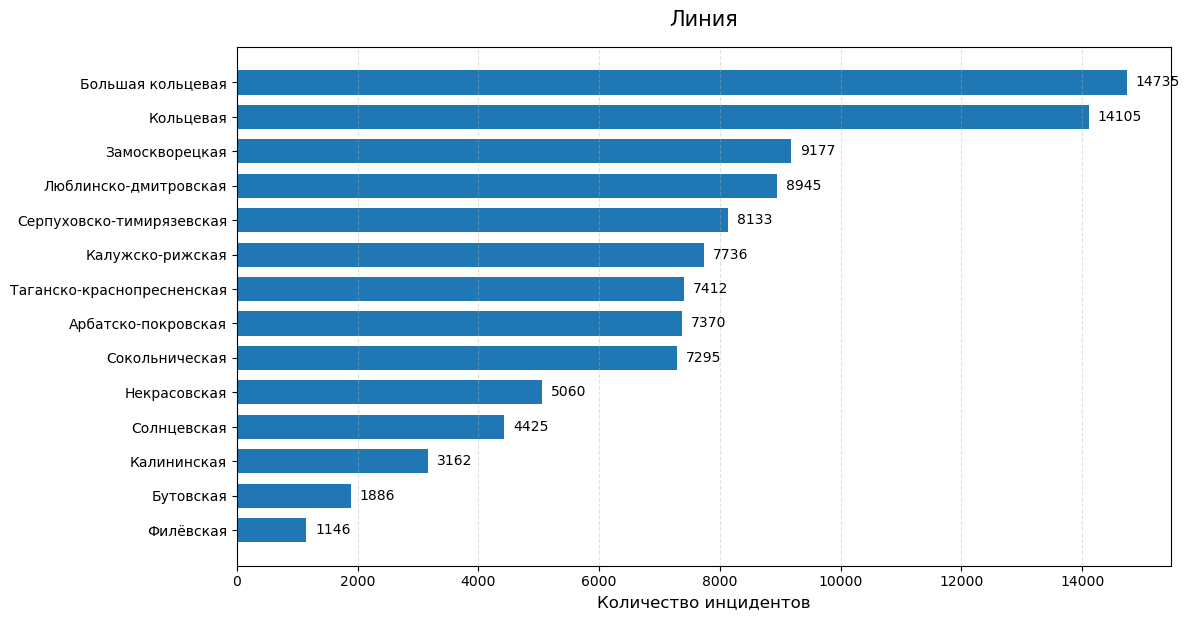

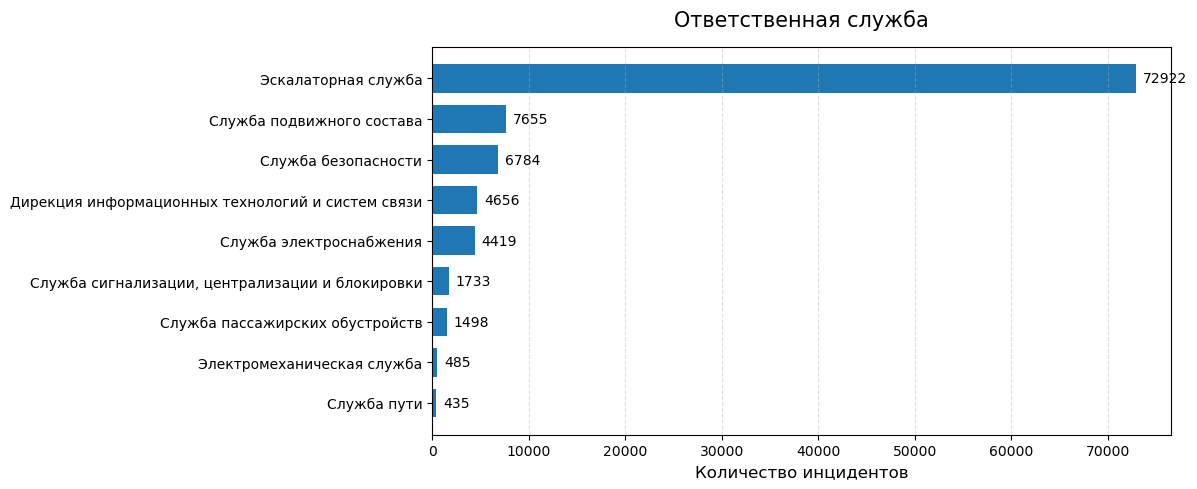

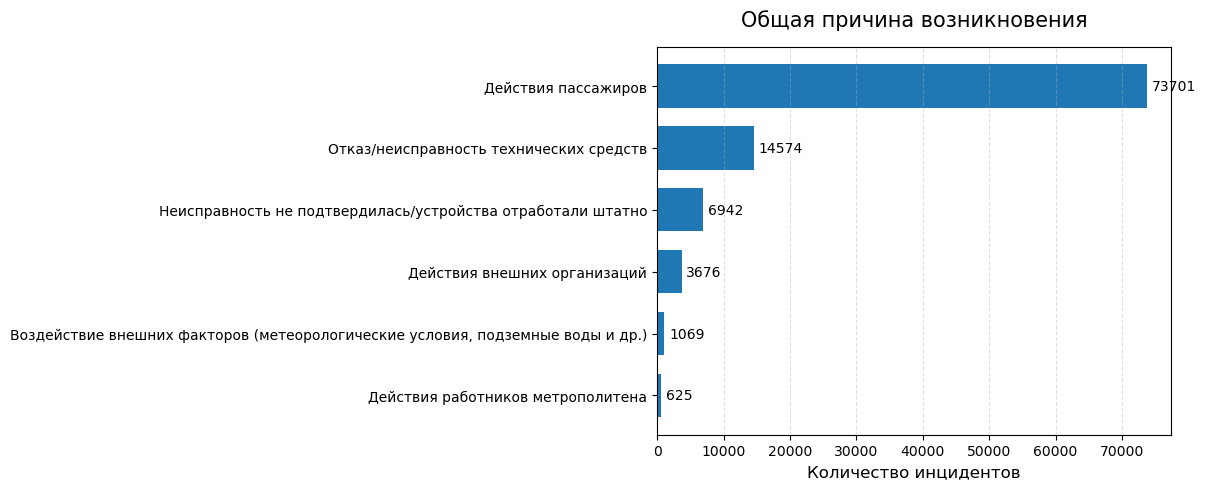

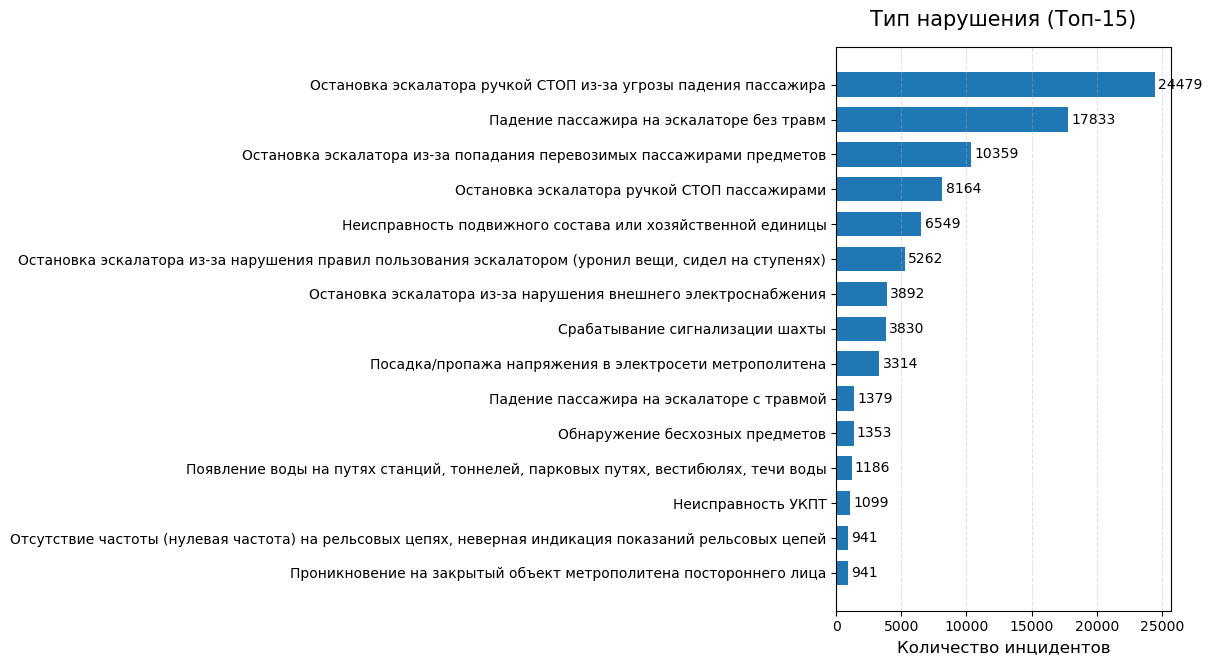

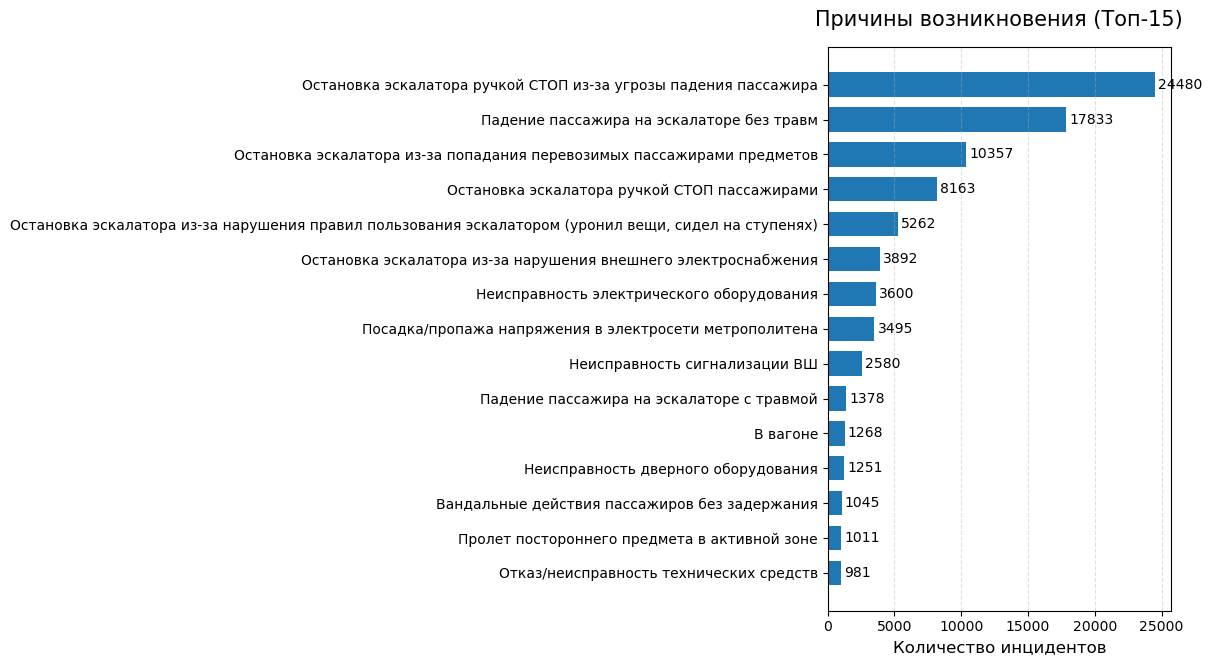

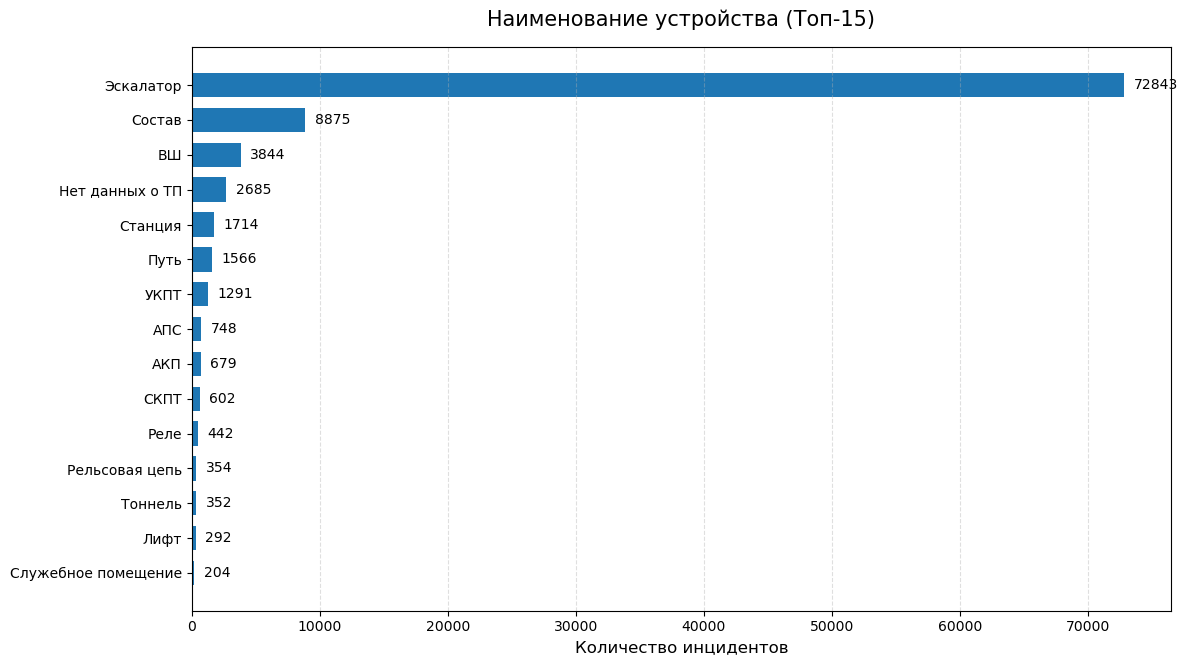

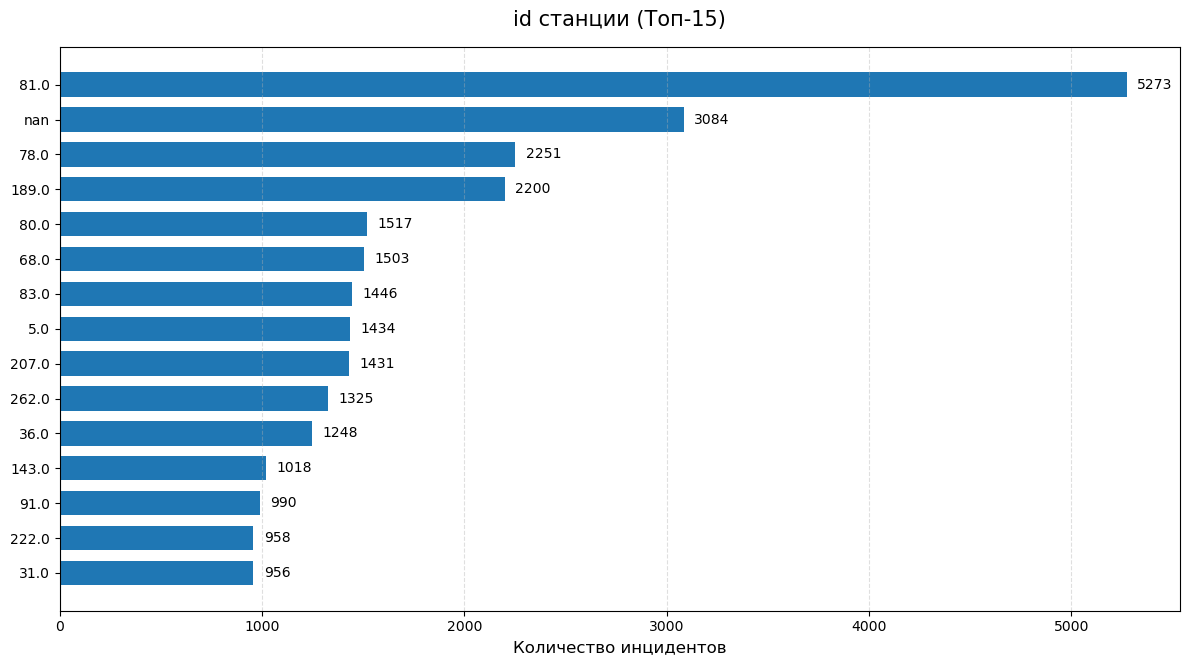

In [74]:
cat_cols = [
    "Линия",
    "Ответственная служба",
    "Общая причина возникновения",
    "Тип нарушения",
    "Причины возникновения",
    "Наименование устройства",
    "id станции"
]

TOP_N = 15

for col in cat_cols:

    counts = data[col].value_counts(dropna=False)

    # Для признаков с большим количеством категорий показываем только Top-N
    if len(counts) > TOP_N:
        counts = counts.head(TOP_N)

    # Самый большой сверху
    counts = counts.sort_values()

    plt.figure(figsize=(12, max(5, len(counts) * 0.45)))

    bars = plt.barh(
        counts.index.astype(str),
        counts.values,
        height=0.7
    )

    plt.title(
        f"{col}" + (f" (Топ-{TOP_N})" if data[col].nunique() > TOP_N else ""),
        fontsize=15,
        pad=15
    )

    plt.xlabel("Количество инцидентов", fontsize=12)
    plt.ylabel("")

    plt.grid(axis="x", linestyle="--", alpha=0.4)

    for bar in bars:
        width = bar.get_width()
        plt.text(
            width + counts.max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{int(width)}",
            va="center",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()

При анализе количества инцидентов по линиям в целом можно отметить, что число инцидентов коррелирует с количеством станций в линии метро (информация о количестве станций из открытых источников). Выделяются среди них Кольцевая линия - топ 2, практически столько же как и на БКЛ при том что более чем в два раза короче, Сокольническая напротив - при высокой длине находится в середине рейтинга.

В основном инциденты возникают из-за действий пассажиров (около 70% всех инцидентов), 15% приходится на проблемы технических средств.
Среди 5 самых частых типов нарушений 4 приходится на инциденты на эскалаторе и лишь на 5 месте нарушение связанное с другим видом нарушения. При этом 7 из 15 самых частых нарушений приходятся на эскалаторы. Остальные графики подтверждают эскалатор как наиболее частое место возникновения инцидентов.

Также можно выделить станцию с id 81, на ней число инцидентов в несколько раз выше чем на любых других станциях.

In [75]:
# Количество станций по линиям
station_count = {
    'Сокольническая': 29,
    'Замоскворецкая': 24,
    'Арбатско-покровская': 26,
    'Филёвская': 13,
    'Кольцевая': 12,
    'Калужско-рижская': 24,
    'Таганско-краснопресненская': 23,
    'Калининская': 8,
    'Серпуховско-тимирязевская': 25,
    'Люблинско-дмитровская': 26,
    'Бутовская': 7,
    'Солнцевская': 14,
    'Некрасовская': 8,
    'Большая кольцевая': 22
}

test_df = (
    data['Линия']
    .value_counts()
    .rename_axis('Линия')
    .reset_index(name='Количество инцидентов')
)

test_df['Количество станций'] = test_df['Линия'].map(station_count)

test_df['Число инцидентов на станцию'] = (
    test_df['Количество инцидентов'] /
    test_df['Количество станций']
)

test_df

,Линия,Количество инцидентов,Количество станций,Число инцидентов на станцию
0,Большая кольцевая,14735,22,669.772727
1,Кольцевая,14105,12,1175.416667
2,Замоскворецкая,9177,24,382.375000
3,Люблинско-дмитровская,8945,26,344.038462
4,Серпуховско-тимирязевская,8133,25,325.320000
5,Калужско-рижская,7736,24,322.333333
6,Таганско-краснопресненская,7412,23,322.260870
7,Арбатско-покровская,7370,26,283.461538
8,Сокольническая,7295,29,251.551724
9,Некрасовская,5060,8,632.500000


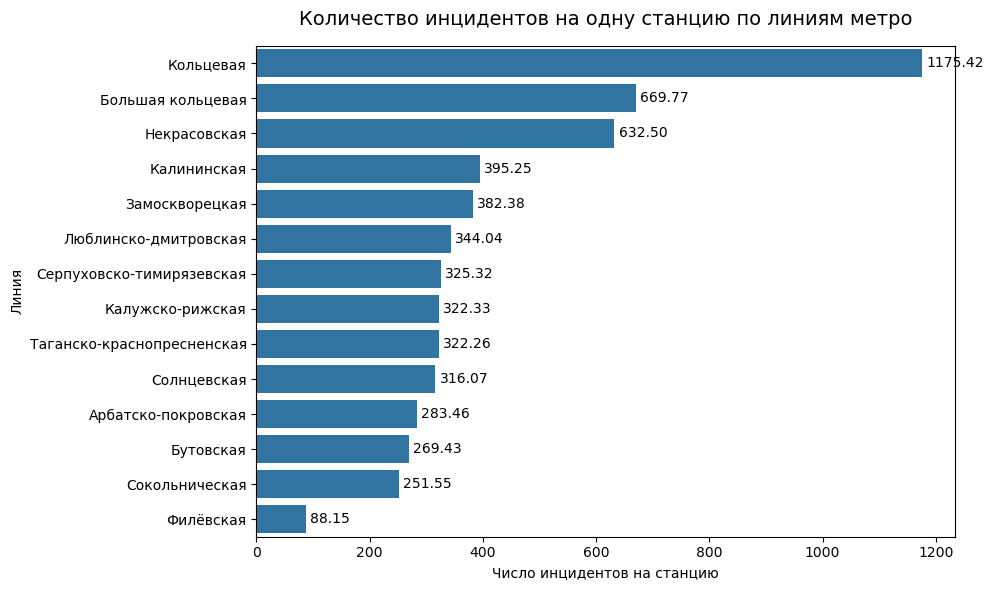

In [76]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=test_df.sort_values('Число инцидентов на станцию', ascending=False),
    y='Линия',
    x='Число инцидентов на станцию'
)

ax.set_title(
    'Количество инцидентов на одну станцию по линиям метро',
    fontsize=14,
    pad=15
)

ax.set_xlabel('Число инцидентов на станцию')
ax.set_ylabel('Линия')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

Если рассматривать число инцидентов на станцию по линиям с учетом числа станций в составе линий, то видно что Кольцевая линия (12 станций) в два раза больше имеет инцидентов на станцию, чем самая длинная линия БКЛ (29 станций).

Предположение относительно Кольцевой линии - на данной линии из 12 станций все 12 являются пересадочными, то есть на каждой есть большое число эскалаторов. С учетом того что большая часть инцидентов приходится на эскалаторы это могло бы объяснить почему Кольцевая линия является лидером с отрывом по числу инцидентов. Также есть предположение связанное с тем, что Кольцевая линия по сути проходит вокруг центра города и во многом связана с местами развлечений и досуга. Эскалатор, являясь объектом повышенной травмоопасности, представляет большую опасность при нахождении на нем лиц в нетрезвом состоянии. Кроме того высокое количество инцидентов вероятно связано с пассажиропотоком, однако без сведений о нем нельзя подтвердить или опровергнуть данное предположение.

### Зависимость причин возникновения инцидентов

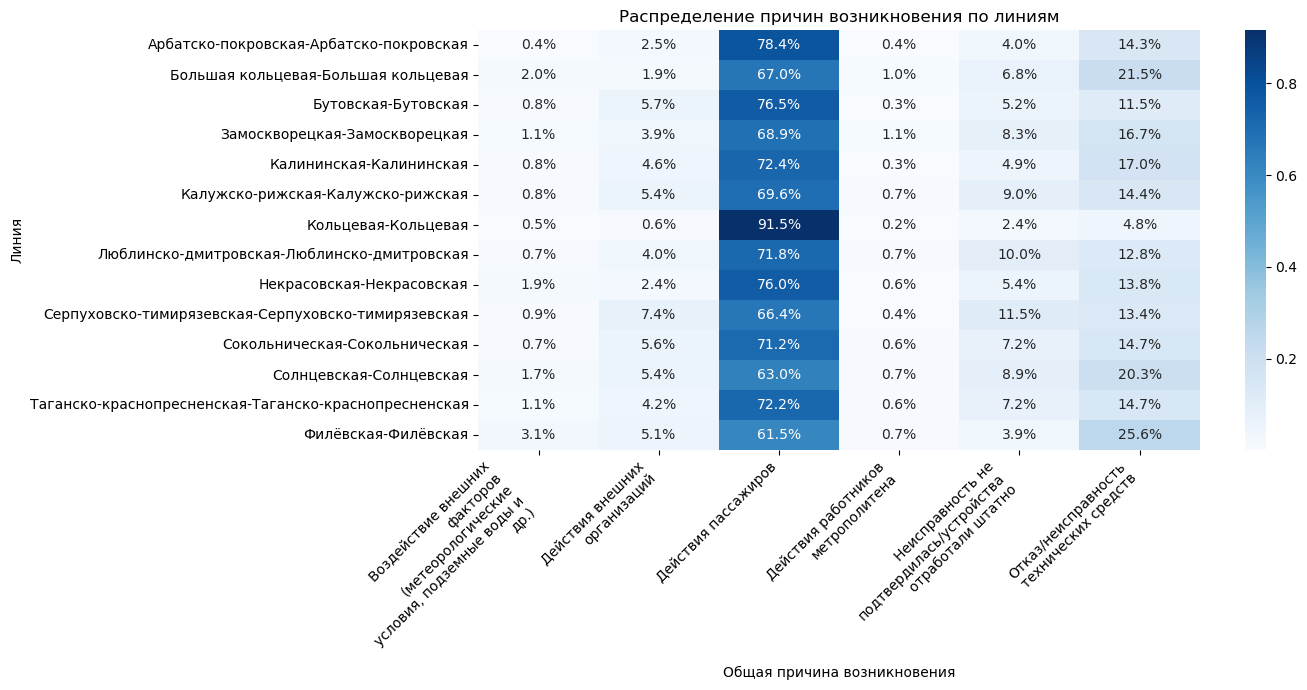

In [77]:
pivot = (
    data
    .groupby(['Линия', 'Общая причина возникновения'])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())
    .unstack(fill_value=0)
)

# Перенос длинных названий причин
pivot.columns = [
    '\n'.join(textwrap.wrap(str(col), width=25))
    for col in pivot.columns
]

plt.figure(figsize=(14, 7))

sns.heatmap(
    pivot,
    annot=True,
    fmt='.1%',
    cmap='Blues'
)

plt.title('Распределение причин возникновения по линиям')
plt.xlabel('Общая причина возникновения')
plt.ylabel('Линия')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

Распределение причин возникновения инцидентов примерно одинаково для большинства линий за исключением Кольцевой - на ней доля инцидентов с пассажирами достигает 90% тогда как на остальных линиях этот показатель 65 - 70 %. Как и в предположениях ранее это может объясняться тем что все станции Кольцевой линии являются пересадочными.

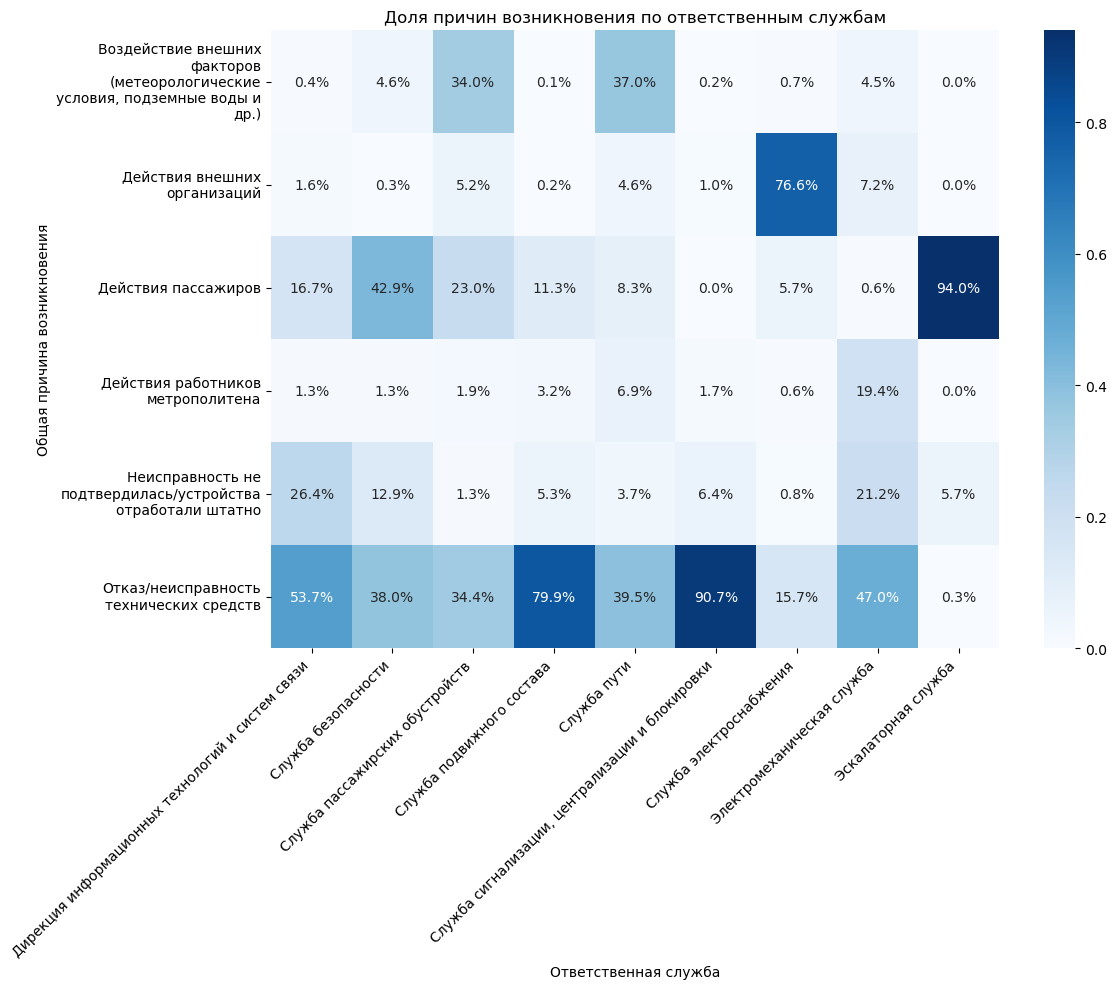

In [78]:
# Группировка: ответственная служба + причина
reason_service = (
    data
    .groupby(['Ответственная служба', 'Общая причина возникновения'])
    .size()
    .reset_index(name='Количество')
)


# Расчет доли причины внутри каждой службы
reason_service['Доля'] = (
    reason_service['Количество'] /
    reason_service.groupby('Ответственная служба')['Количество']
    .transform('sum')
)


# Оставляем самые распространенные причины
top_reasons = (
    reason_service
    .groupby('Общая причина возникновения')['Количество']
    .sum()
    .nlargest(7)
    .index
)


plot_df = reason_service[
    reason_service['Общая причина возникновения'].isin(top_reasons)
]


pivot_2 = (
    plot_df
    .pivot(
        index='Ответственная служба',
        columns='Общая причина возникновения',
        values='Доля'
    )
    .fillna(0)
)


pivot_2.columns = [
    '\n'.join(textwrap.wrap(str(col), width=25))
    for col in pivot_2.columns
]


plt.figure(figsize=(12, 10))

sns.heatmap(
    pivot_2.T,
    annot=True,
    fmt='.1%',
    cmap='Blues'
)


plt.title(
    'Доля причин возникновения по ответственным службам'
)

plt.xlabel('Ответственная служба')
plt.ylabel('Общая причина возникновения')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

Анализ распределения причин возникновения внутри ответственных служб показывает выраженную специализацию источников инцидентов. Для технических служб (подвижной состав, СЦБ) доминирующей причиной являются отказы технических средств (80–91%). Эскалаторная служба характеризуется преимущественно пассажирскими факторами (94%), что указывает на значительную роль человеческого поведения. Отдельно выделяется служба электроснабжения, где большинство инцидентов связано с действиями внешних организаций (76%), что может свидетельствовать о влиянии сторонних работ и внешней инфраструктуры.

### Анализ инцидентов с участием остановки поездов/задержки поездов/высадки пассажиров

In [79]:
num_cols = data.select_dtypes(include='number').columns.difference(cat_cols).tolist()

zero_stats = pd.DataFrame({
    'Количество нулей': [
        (data[col] == 0).sum()
        for col in num_cols
    ],
    'Доля нулей': [
        (data[col] == 0).mean()
        for col in num_cols
    ]
}, index=num_cols)

zero_stats['Доля нулей'] = (
    zero_stats['Доля нулей']
    .map(lambda x: f'{x:.1%}')
)

zero_stats

,Количество нулей,Доля нулей
Кол-во внеплановых высадок пассажиров,94638,94.1%
Кол-во минут опоздания,100365,99.8%
Кол-во опоздавших поездов,100365,99.8%
Кол-во полных отмен,100231,99.6%
Кол-во участковых отмен,93596,93.0%
"Перерыв в движении, мин",100407,99.8%


Практически все случаи происходили без вмешательства в движение поездов. Это логично с учетом того что подавляющее число инцидентов приходится на эскалатор.

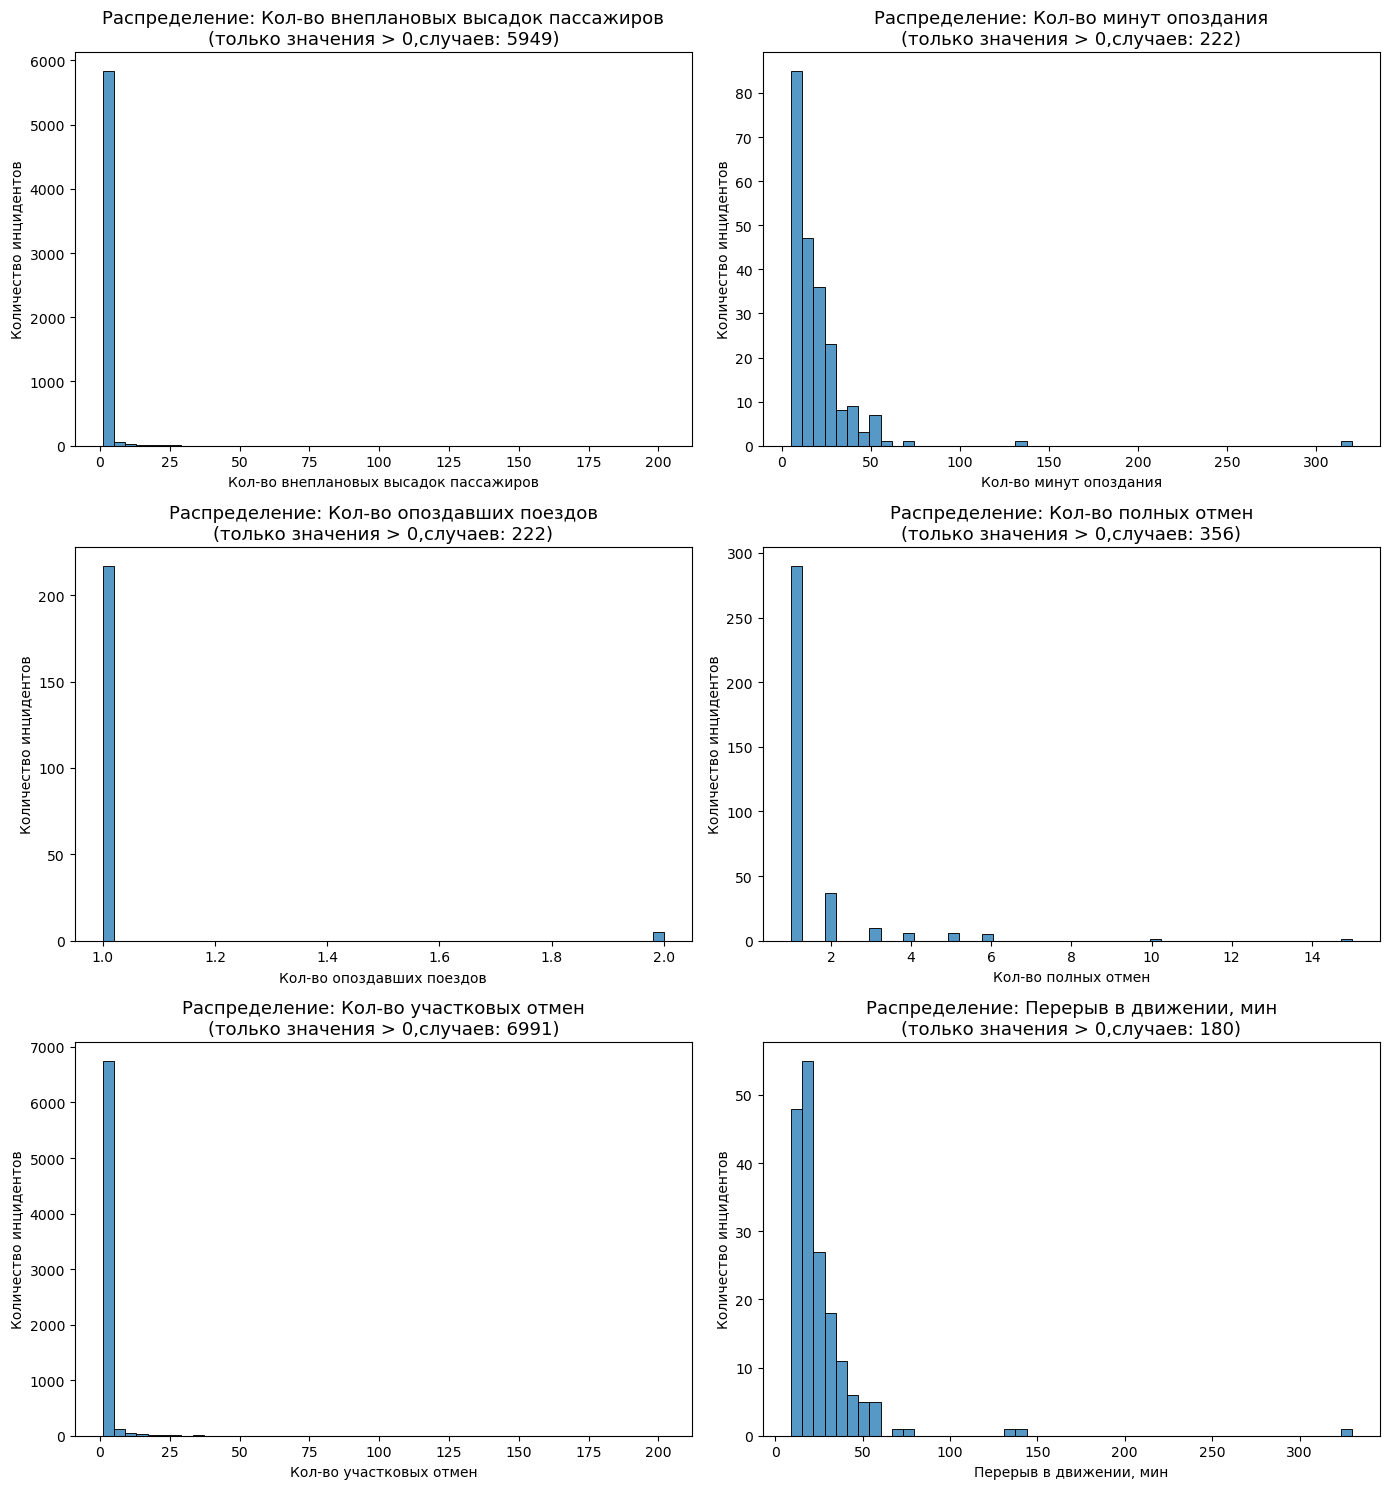

In [80]:
ncols = 2
nrows = (len(num_cols) + 1) // 2

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(14, 5 * nrows)
)

axes = axes.flatten()

for ax, col in zip(axes, num_cols):

    # берем только случаи с ненулевым значением
    plot_data = data[data[col] > 0]

    sns.histplot(
        data=plot_data,
        x=col,
        bins=50,
        ax=ax
    )

    ax.set_title(
        f'Распределение: {col}\n(только значения > 0,случаев: {len(plot_data)})',
        fontsize=13
    )

    ax.set_xlabel(col)
    ax.set_ylabel('Количество инцидентов')


for ax in axes[len(num_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

Все случаи с инцидентами задержки/отмены поездов имеют значительный максимум у нуля (экспоненциальное распределение). То есть как правило при возникновении инцидентов с поездами все ограничивается локальными мероприятиями.

C:\Users\Ivan Kravchenko\AppData\Local\Temp\ipykernel_20624\2331783694.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


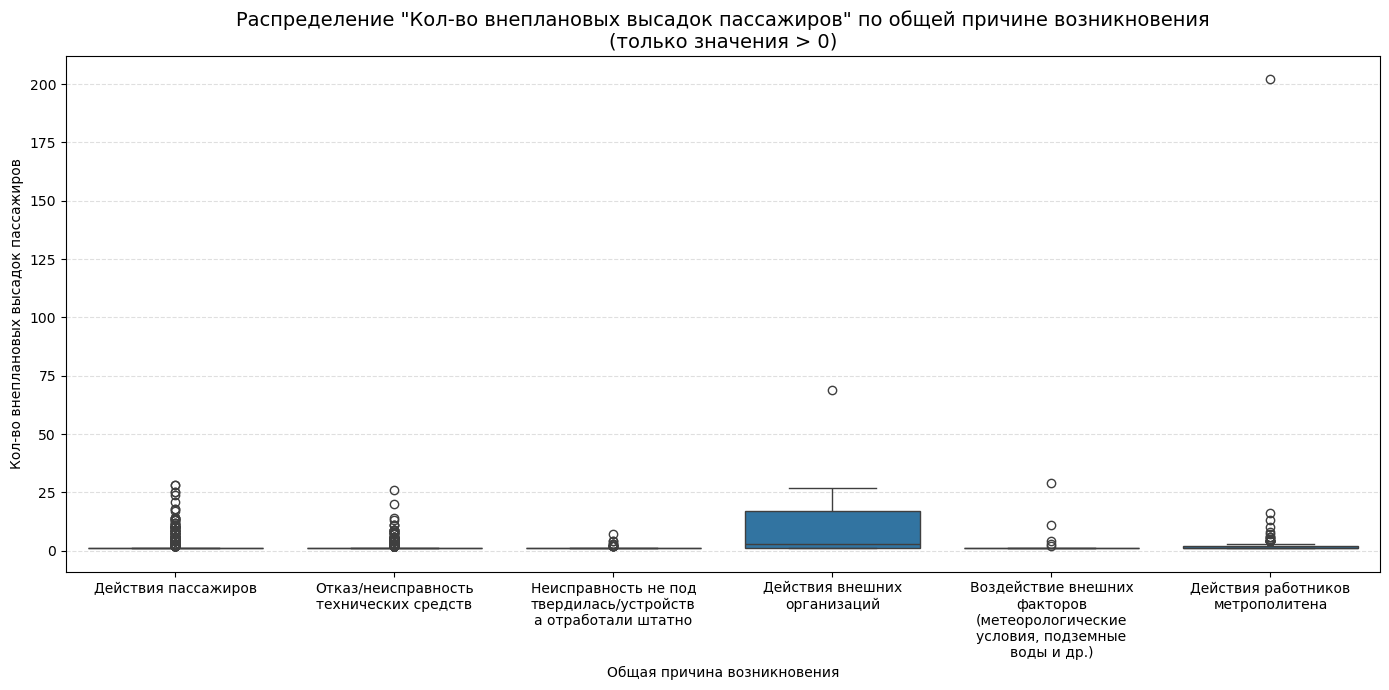

C:\Users\Ivan Kravchenko\AppData\Local\Temp\ipykernel_20624\2331783694.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


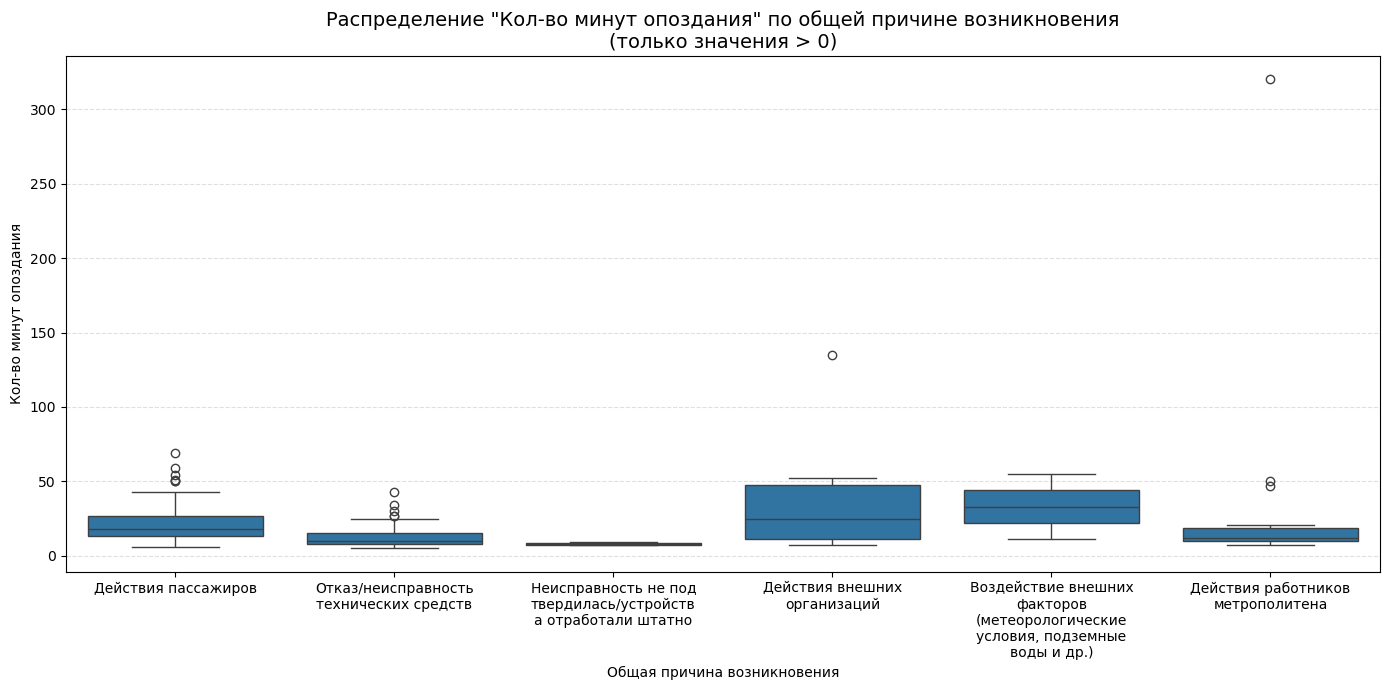

C:\Users\Ivan Kravchenko\AppData\Local\Temp\ipykernel_20624\2331783694.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


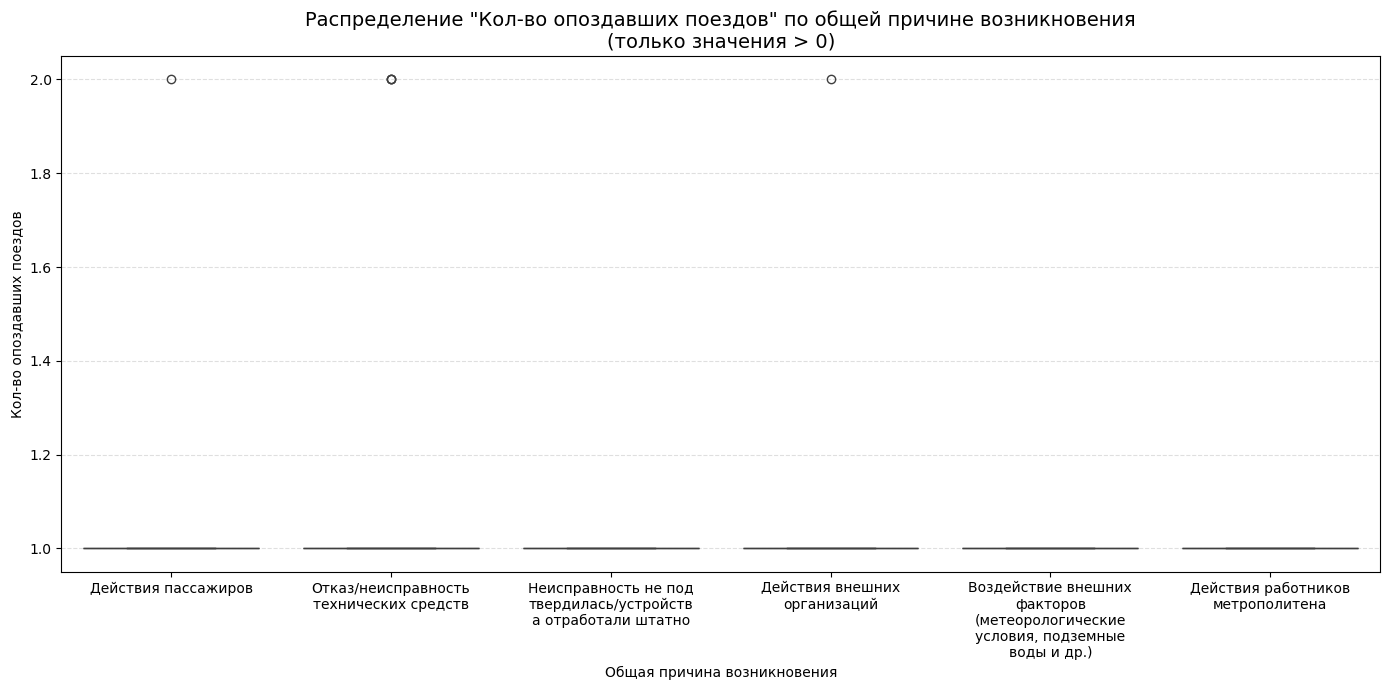

C:\Users\Ivan Kravchenko\AppData\Local\Temp\ipykernel_20624\2331783694.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


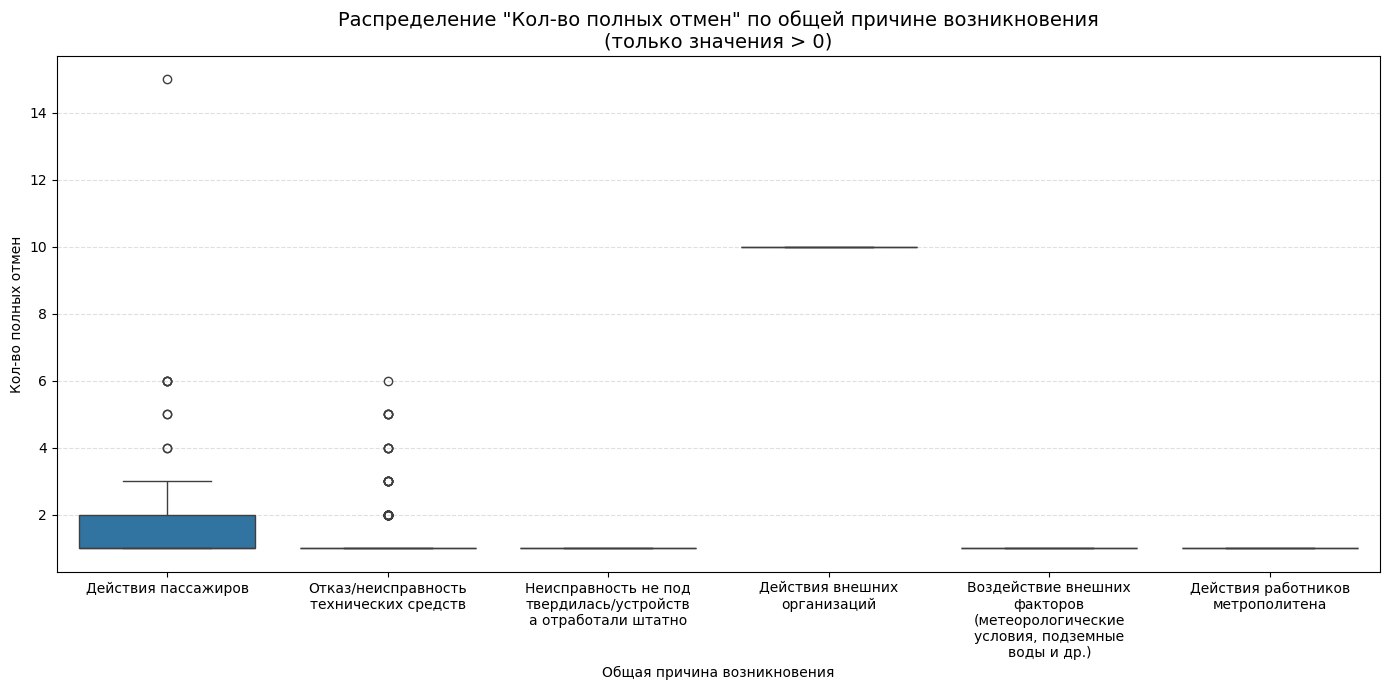

C:\Users\Ivan Kravchenko\AppData\Local\Temp\ipykernel_20624\2331783694.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


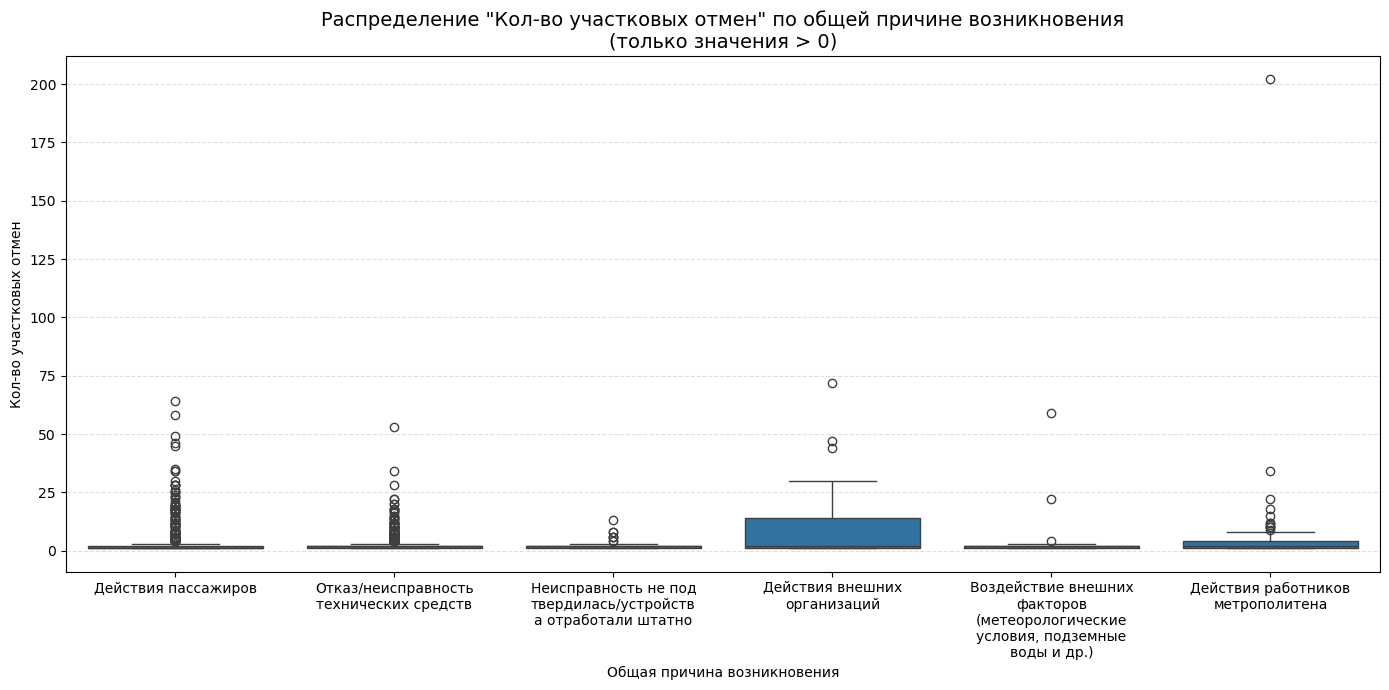

C:\Users\Ivan Kravchenko\AppData\Local\Temp\ipykernel_20624\2331783694.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


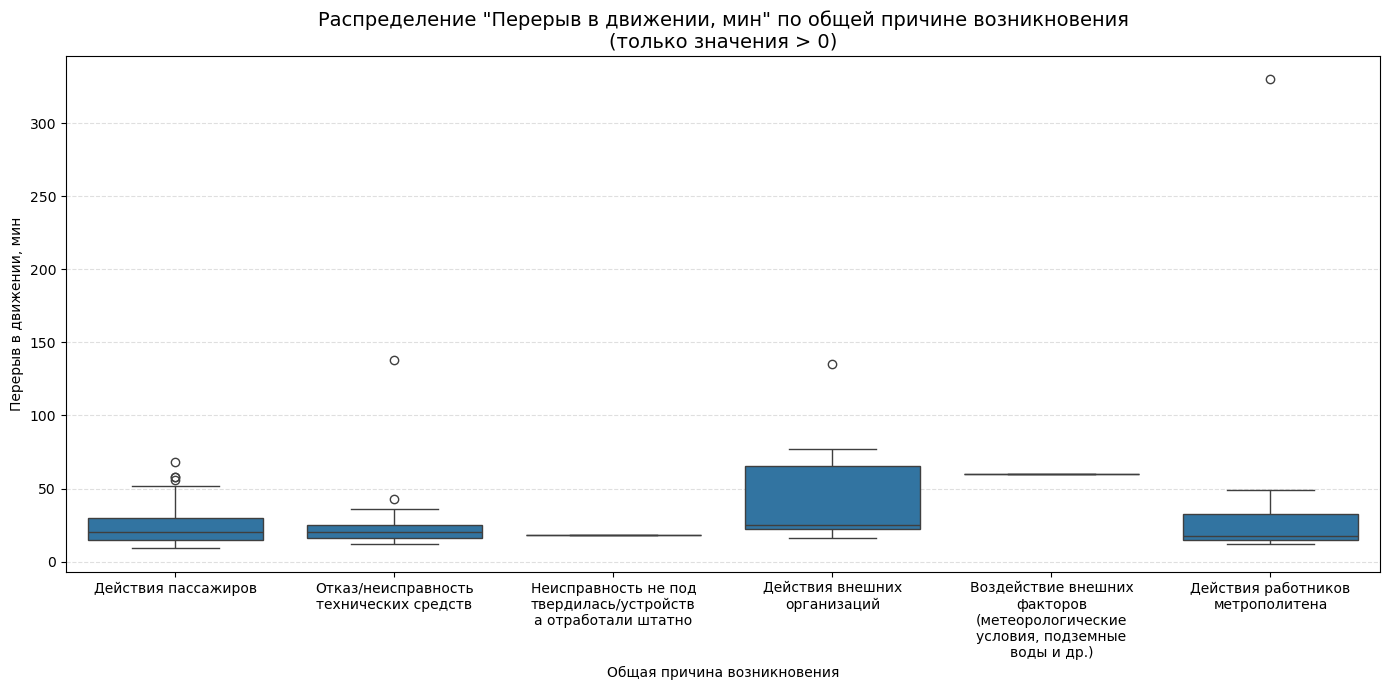

In [81]:
# единый порядок причин для всех графиков
cause_order = (
    data['Общая причина возникновения']
    .value_counts()
    .index
)

for col in num_cols:

    # только случаи, где показатель присутствует
    plot_data = data[data[col] > 0]

    plt.figure(figsize=(14, 7))

    ax = sns.boxplot(
        data=plot_data,
        x='Общая причина возникновения',
        y=col,
        order=cause_order
    )

    labels = [
        '\n'.join(textwrap.wrap(str(label), width=20))
        for label in cause_order
    ]

    ax.set_xticklabels(
        labels,
        rotation=0,
        ha='center'
    )

    plt.title(
        f'Распределение "{col}" по общей причине возникновения\n'
        '(только значения > 0)',
        fontsize=14
    )

    plt.xlabel('Общая причина возникновения')
    plt.ylabel(col)

    plt.grid(
        axis='y',
        linestyle='--',
        alpha=0.4
    )

    plt.tight_layout()
    plt.show()

Для большинства случаев с инцидентами причиной в основном являются действия внешних организаций. Исключением являются случаи с количеством полных отмен, которые в основном вызываются действиями пассажиров.

### Анализ временных закономерностей инцидентов

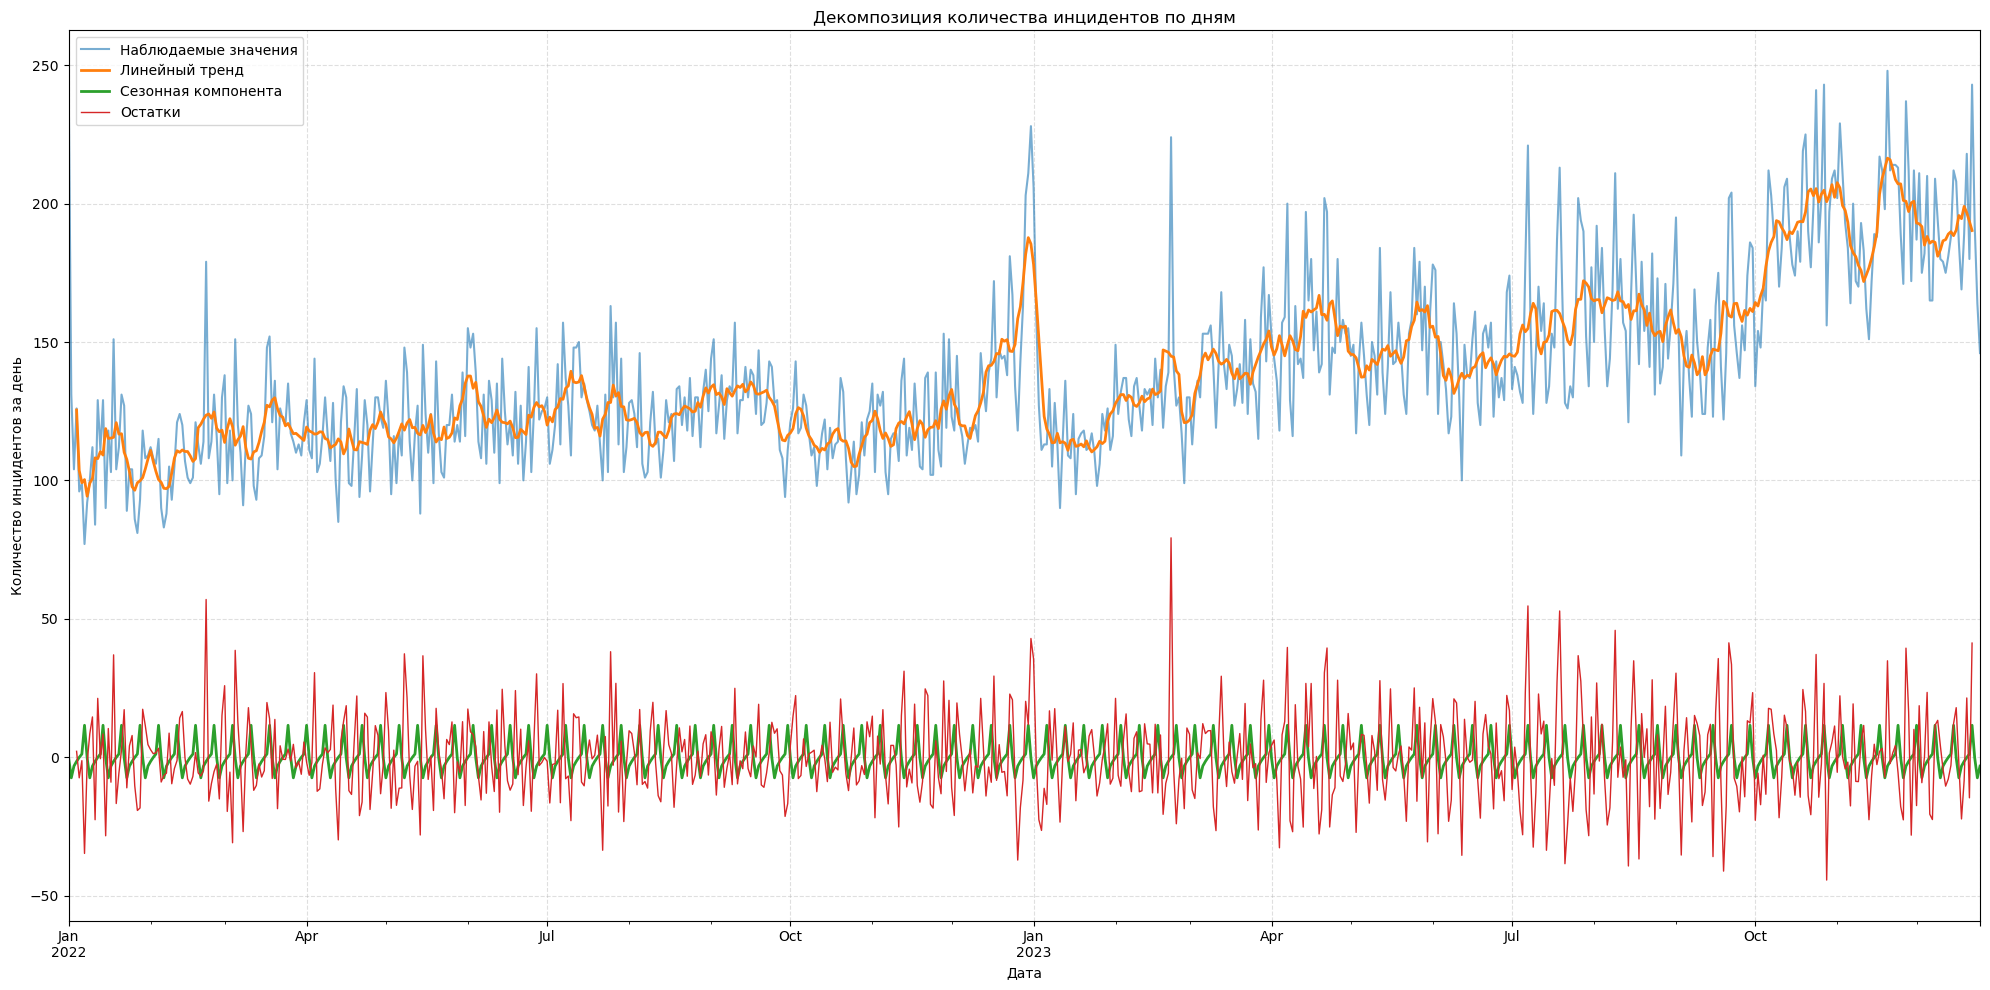

In [82]:
# временной ряд: количество инцидентов по дням
daily_counts = (data.set_index('Начало случая').resample('D').size())

# декомпозиция
decomposition = seasonal_decompose(daily_counts, model='additive', period=7)

fig, ax = plt.subplots(figsize=(20, 10))

# исходные наблюдения
daily_counts.plot(ax=ax, label='Наблюдаемые значения', alpha=0.6)

# тренд
decomposition.trend.plot(ax=ax, label='Линейный тренд', linewidth=2)

# сезонность
decomposition.seasonal.plot(ax=ax, label='Сезонная компонента', linewidth=2)

# остатки
decomposition.resid.plot(ax=ax, label='Остатки', linewidth=1)

plt.title('Декомпозиция количества инцидентов по дням')

plt.ylabel('Количество инцидентов за день')

plt.xlabel('Дата')

plt.legend()

plt.grid(linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Видна тенденция общего роста числа инцидентов за весь период наблюдений. Кроме того видно, что в конце декабря - начале января было особенно много случаев - возможно это связано с длинными праздничными выходными.

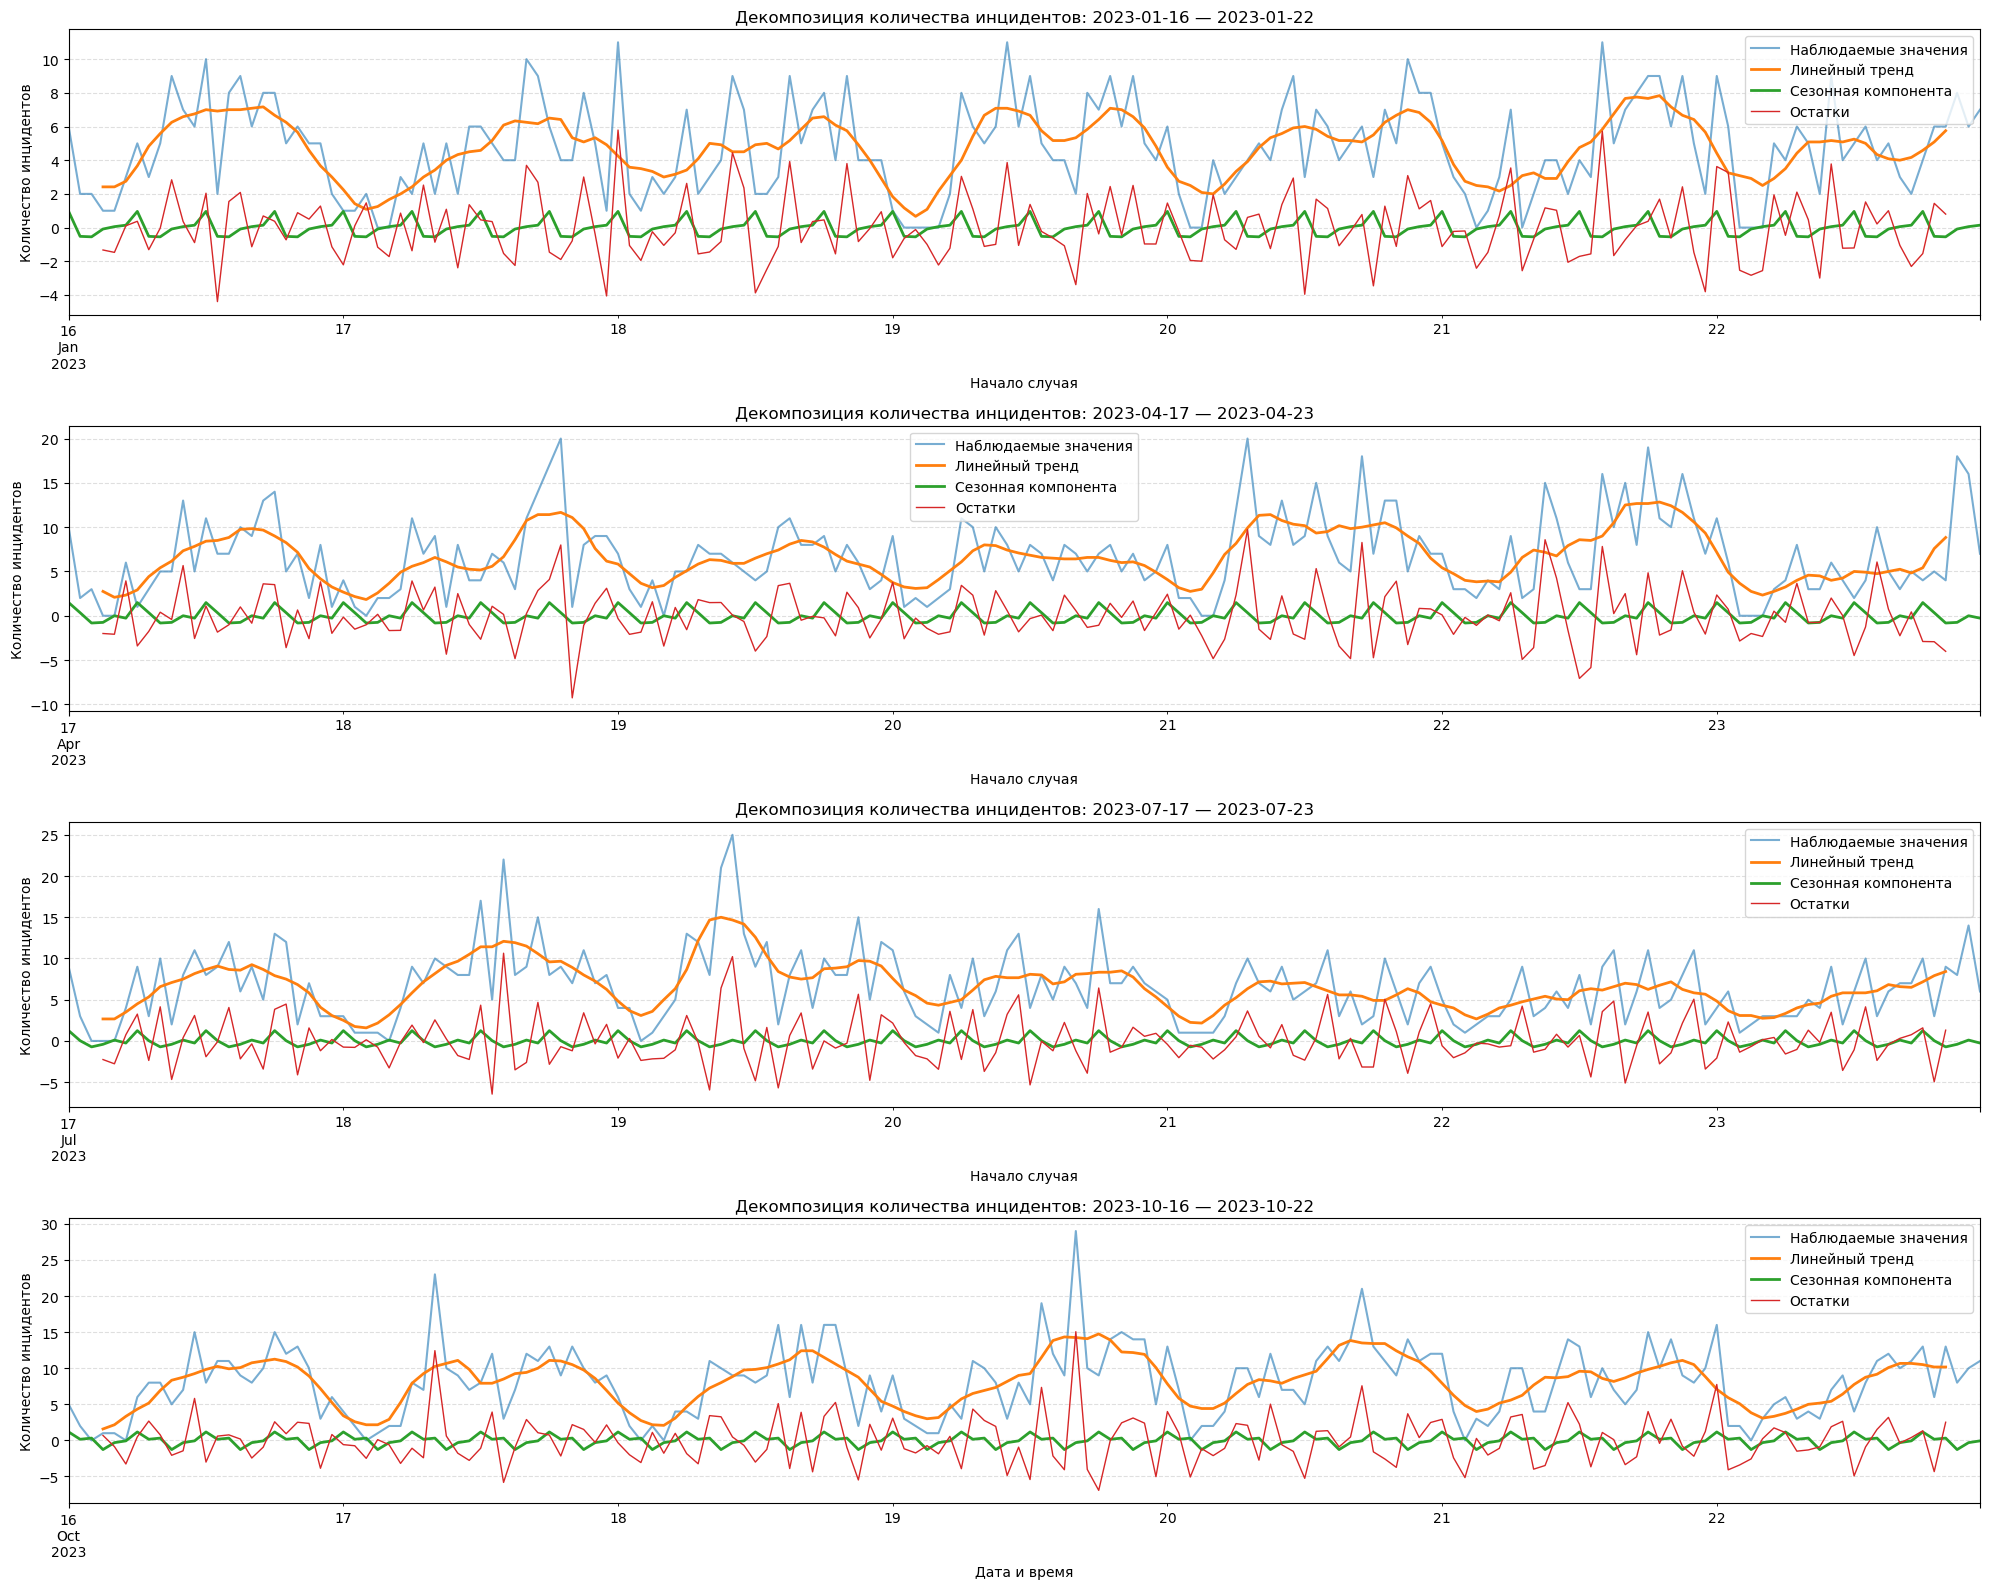

In [83]:
# количество инцидентов по часам
hourly_counts = (data.set_index('Начало случая').resample('h').size())


# Недели для анализа (понедельник - воскресенье)
weeks = [
    '2023-01-16',
    '2023-04-17',
    '2023-07-17',
    '2023-10-16'
]


fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(20, 16))


for ax, week in zip(axes, weeks):

    start = pd.Timestamp(week)
    end = start + pd.Timedelta(days=7)

    # данные за неделю
    week_data = hourly_counts.loc[start:end - pd.Timedelta(hours=1)]

    # декомпозиция с 6-часовой сезонностью
    decomposition = seasonal_decompose(week_data, model='additive', period=6)

    # наблюдаемые значения
    decomposition.observed.plot(ax=ax, label='Наблюдаемые значения', alpha=0.6)

    # тренд
    decomposition.trend.plot(ax=ax, label='Линейный тренд', linewidth=2)

    # сезонность
    decomposition.seasonal.plot(ax=ax, label='Сезонная компонента', linewidth=2)

    # остатки
    decomposition.resid.plot(ax=ax, label='Остатки', linewidth=1)

    ax.set_title(f'Декомпозиция количества инцидентов: {start.date()} — {(end - pd.Timedelta(days=1)).date()}')
    ax.set_ylabel('Количество инцидентов')
    ax.grid(linestyle='--', alpha=0.4)
    ax.legend()


plt.xlabel('Дата и время')
plt.tight_layout()
plt.show()

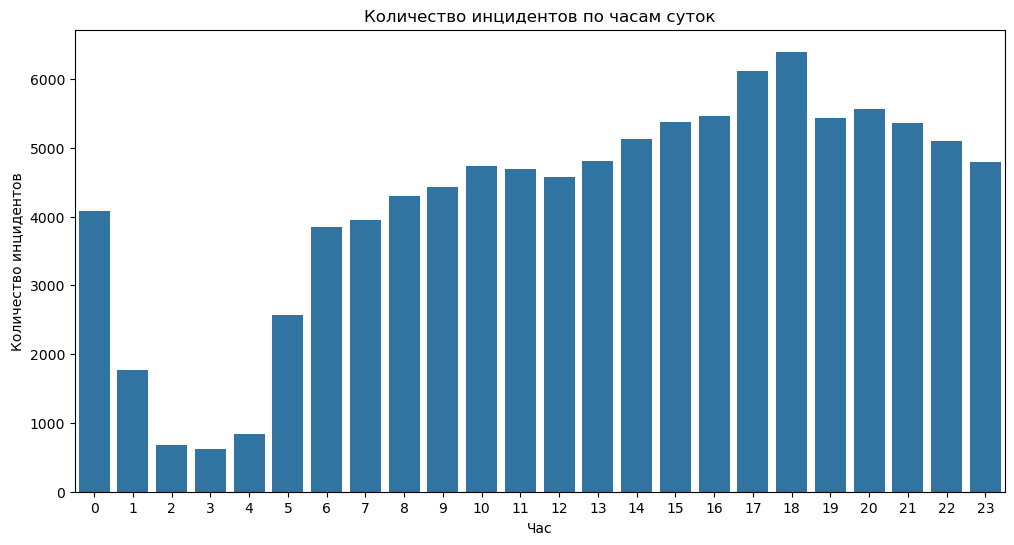

In [84]:
data['hour'] = data['Начало случая'].dt.hour

hourly_counts = data['hour'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
sns.barplot(x=hourly_counts.index, y=hourly_counts.values)
plt.title('Количество инцидентов по часам суток')
plt.xlabel('Час')
plt.ylabel('Количество инцидентов')
plt.show()

Видно, что пик числа инцидентов приходится на вечерний час пик - 17-18 часов. Провал от 0 до 6 часов нормален, поскольку в этот период метро не работает на вход и перевозку пассажиров. Стоит отметить, что на графике сильно не выделяется утренний час пик (локальный максимум в районе 10 часов), возможно в утренние часы люди более равномерно прибывают в метро с учетом времени необходимого на проезд, а заканчивается рабочее время у всех примерно одинаково, но для подтверждения или опровержения данной гипотезы необходимы сведения о пассажиропотоке.

Во временных рядах за 23 год, видно, что несмотря на общую сохраняющуюся структуру распределения инцидентов, общее число инцидентов растет от января к октябрю.

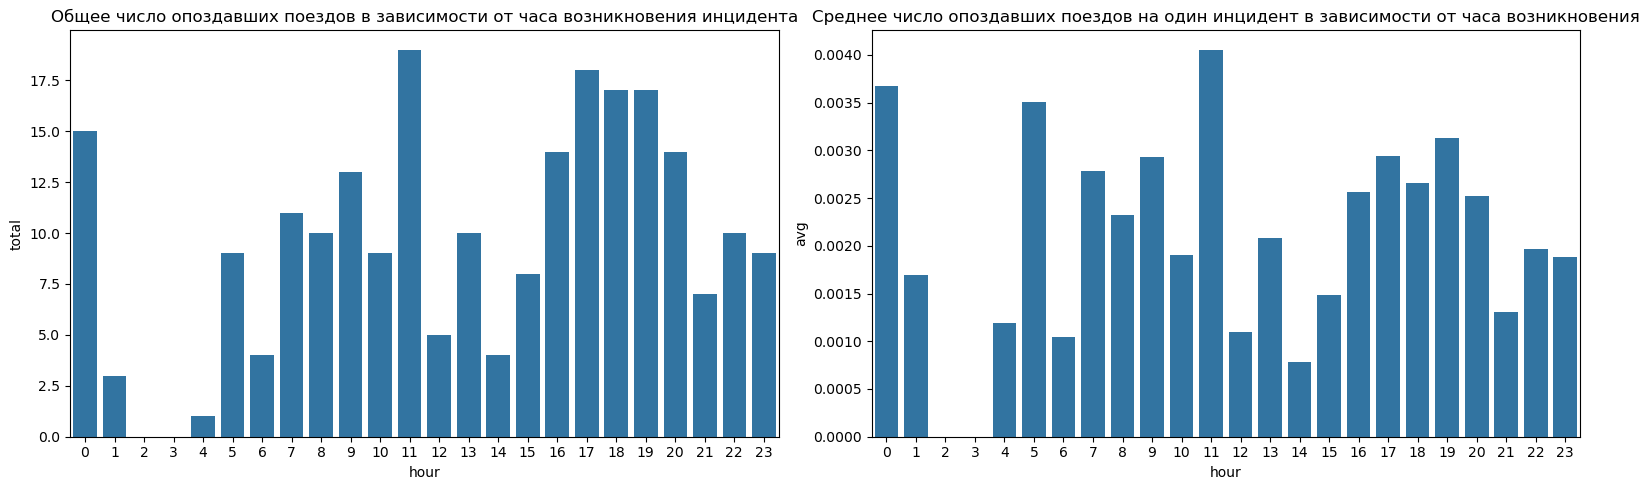

In [85]:
hourly_delay = data.groupby('hour')['Кол-во опоздавших поездов'].agg(
    total='sum',      # суммарный эффект в час
    avg='mean',        # средний эффект на один инцидент
    n='count'
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=hourly_delay.index, y=hourly_delay['total'], ax=axes[0])
axes[0].set_title('Общее число опоздавших поездов в зависимости от часа возникновения инцидента')

sns.barplot(x=hourly_delay.index, y=hourly_delay['avg'], ax=axes[1])
axes[1].set_title('Среднее число опоздавших поездов на один инцидент в зависимости от часа возникновения')

plt.tight_layout()
plt.show()

Опоздания поездов имеют схожее распределение с поведением всех инцидентов, однако имеют более ярко выраженную зависимость от часов. Максимальное число проблем наблюдается в 11, 17-19 часов и околополуночное время. Значения среднего числа опозданий на один инцидент в целом согласуется с общим числом инцидентов (больше инцидентов — большее значение среднего числа опозданий на каждый инцидент, что может быть связано с цепной реакцией). Однако выделяются утренние часы — в районе 5 утра, в данный период даже редкие инциденты могут приводить к большему числу задержек. Точно утверждать об этом не представляется возможным, поскольку именно на этот период приходится открытие метро и запуск первых поездов, для уточнения требуется больше сторонних данных.

## Корреляционный анализ

In [86]:
num_cols = [
    'Перерыв в движении, мин',
    'Кол-во опоздавших поездов',
    'Кол-во минут опоздания',
    'Кол-во полных отмен',
    'Кол-во участковых отмен',
    'Кол-во внеплановых высадок пассажиров'
]
corr_matrix = data.drop(['Начало случая', 'Окончание случая', 'Наименование детали устройства'], axis=1).phik_matrix(interval_cols=num_cols)
display(corr_matrix)

,"Перерыв в движении, мин",id станции,Станционный путь,Перегон,Кол-во опоздавших поездов,Кол-во минут опоздания,Кол-во полных отмен,Кол-во участковых отмен,Кол-во внеплановых высадок пассажиров,Линия,Ответственная служба,Тип нарушения,Причины возникновения,Наименование устройства,Общая причина возникновения,hour
"Перерыв в движении, мин",1.000000,0.120695,0.009841,0.000000,0.382985,0.982076,0.510816,0.956753,0.824180,0.000000,0.053228,0.817821,0.396228,0.324728,0.032484,0.000000
id станции,0.120695,1.000000,0.736788,NaN,0.104647,0.136284,0.095250,0.126975,0.147673,1.000000,0.609130,0.774362,0.786696,0.902737,0.555143,0.271348
Станционный путь,0.009841,0.736788,1.000000,NaN,0.015258,0.000000,0.000000,0.000000,0.000000,0.318141,0.157744,0.489866,0.501120,0.469087,0.120462,0.124530
Перегон,0.000000,NaN,NaN,1.000000,0.000000,0.000000,0.000000,0.475477,0.000000,0.999891,0.774444,0.904449,0.920187,0.919410,0.686917,0.422194
Кол-во опоздавших поездов,0.382985,0.104647,0.015258,0.000000,1.000000,0.475195,0.641528,0.387377,0.347892,0.027026,0.178308,0.463518,0.581962,0.308949,0.125845,0.014810
Кол-во минут опоздания,0.982076,0.136284,0.000000,0.000000,0.475195,1.000000,0.652666,0.974047,0.873630,0.000000,0.057366,0.801845,0.354240,0.067298,0.032504,0.000000
Кол-во полных отмен,0.510816,0.095250,0.000000,0.000000,0.641528,0.652666,1.000000,0.500187,0.745731,0.027657,0.071512,0.135031,0.262440,0.000000,0.046342,0.020068
Кол-во участковых отмен,0.956753,0.126975,0.000000,0.475477,0.387377,0.974047,0.500187,1.000000,0.888951,0.006574,0.051184,0.805394,0.392760,0.295253,0.033060,0.000000
Кол-во внеплановых высадок пассажиров,0.824180,0.147673,0.000000,0.000000,0.347892,0.873630,0.745731,0.888951,1.000000,0.000000,0.048922,0.853805,0.221952,0.266502,0.038614,0.000000
Линия,0.000000,1.000000,0.318141,0.999891,0.027026,0.000000,0.027657,0.006574,0.000000,1.000000,0.219538,0.493002,0.539338,0.441500,0.203032,0.097114


Признаки Начало случая, Окончание случая и Наименование детали устройства удалены из-за чрезмерно высокого количества уникальных значений. Расчет матрицы корреляции с ними невозможен или занимает слишком много времени.

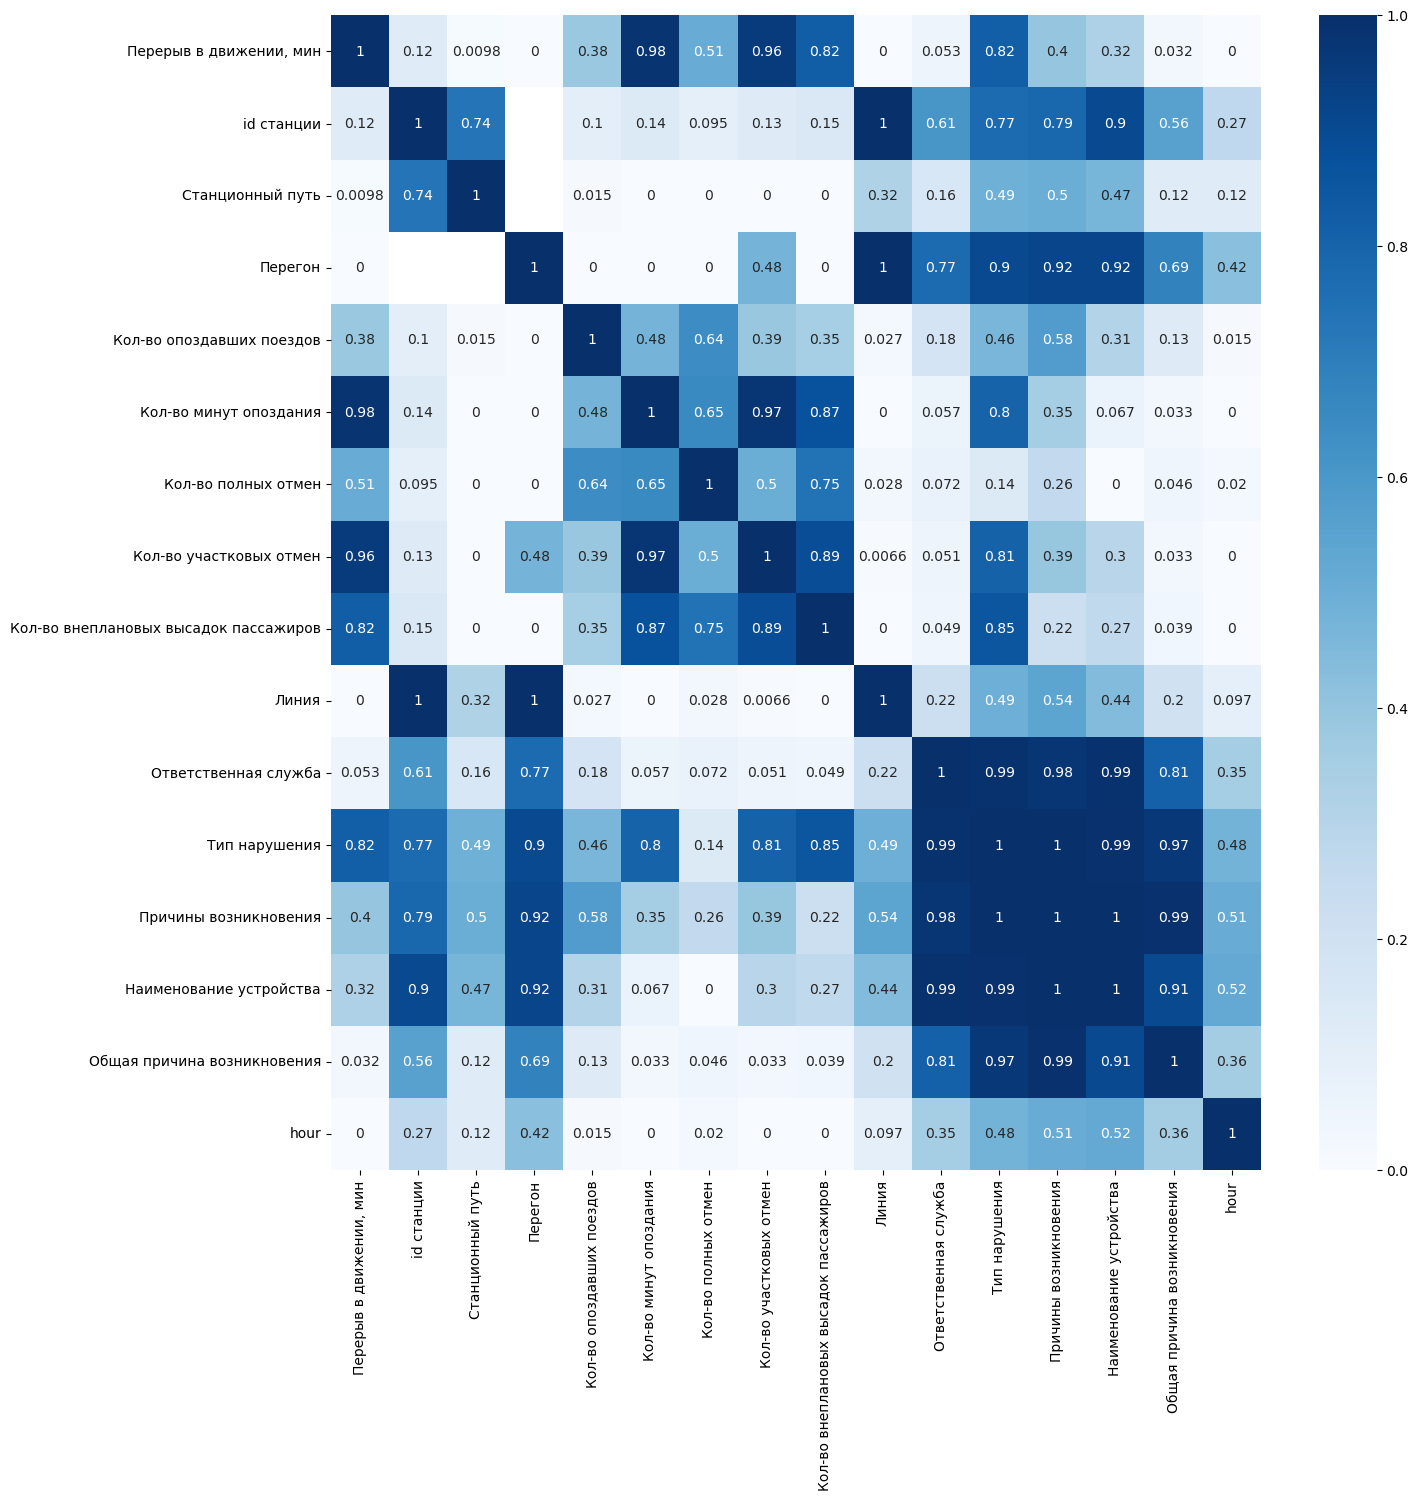

In [87]:
plt.figure(figsize=(15, 15))
sns.heatmap(corr_matrix, annot=True, cmap='Blues');

Матрица корреляции.
Признаки Перерыв в движении, мин, Кол-во участковых отмен и Кол-во внеплановых высадок пассажиров сильно коррелируют с 'Типом нарушения' (более 0.8). При этом Кол-во опоздавших поездов имеет умеренную корреляцию (около 0.4) с Типом нарушения. Все эти метрики последствий довольно слабо коррелируют с Причинами возникновения (в пределах 0.1 - 0.5). Это говорит о том, что последствия в основном определяются типом нарушения, а не конкретной причиной.

Кол-во полных отмен не имеет достаточно сильных корреляций с каким-либо из представленных признаков, что, вероятно, говорит о том, что полная отмена в значительной степени зависит от других факторов, не учтенных в данной таблице.

Кол-во опоздавших поездов имеет сильную корреляцию с Кол-во минут опоздания (0.97), что логично, так как одно прямо влияет на другое. Однако, с остальными признаками Кол-во опоздавших поездов имеет слабые корреляции. Гипотеза - количество опоздавших поездов определяется дополнительными факторами, например временем суток, в которые произошел инцидент (в час пик опоздавших поездов будет больше, чем в период последних или первых поездов).

Наименование устройства, напротив, сильно коррелирует с Типом нарушения и Причинами возникновения (около 0.9). Это позволяет предположить, что само по себе устройство инцидента в значительной степени определяет его тип и причину возникновения.

## Выводы

1. Исходные данные

    В данных было малое число дубликатов, которые были удалены. Было выявлено большое число пропусков в информации о Станционном пути, Перегоне и Наименовании детали.

    Была выявлена аномалия в информации касающейся года начала инцидента. В исходном виде, все инциденты начинались в 1974 - 1975 году, что выглядело нелогичным с учетом того, что окончания инцидентов имели 2022 - 2023 года. Было принято решение счесть ошибочными года начал и скорректировать на основании года окончания инцидента.

2. Исследование ключевых источников проблем

    7 из 15 самых частых типов нарушений и 4 из 5 лидеров рейтинга связаны с эскалаторами. Для большинства линий доля инцидентов связанных с действиями пассажиров 65 - 70 %.

    Основываясь на том факте, что общая причина возникновения имеет очень сильную корреляцию с наименованием устройства, а также том, что для Эскалаторной службы (ЭС) 94 % инцидентов связаны с действиями пассажиров, можно предположить что основным источником инцидентов является именно эскалатор и сопряженные с ним элементы.

    Отдельно можно выделить Кольцевую линию. На ней доля инцидентов с действиями пассажиров составляет 90 %. При этом Кольцевая линия занимает 2-е место по общему количеству инцидентов и 1-е место в рейтинге по количеству инцидентов на одну станцию в линии. Оба этих наблюдения вероятно связаны с тем фактом, что на Кольцевой линии из 12 станций все являются пересадочными.

    Отдельно можно выделить и станцию у которой id 81 - на ней количество инцидентов в несколько раз выше чем на большинстве других станций. Более подробно этот вопрос можно изучить если сопоставить id станций с их реальными названиями или как-либо привязать их к линиям.

    Из наблюдений также стоит отметить, что Служба электроснабжения (Э) как правило связана с инцидентами произошедшими из-за действий внешних организаций.

3. Временные закономерности

    Наблюдается глобальный тренд к увеличению числа инцидентов от 22 к 23 году. Также наблюдается значительный всплеск инцидентов в январе 2023 года. Предположительно это может быть связано с длинными праздничными нерабочими днями и как следствие с повышением потока пассажиров. Однако для подтверждения данного предположения стоит рассмотреть данные за декабрь 2021 - январь 2022 годов и декабрь 2023 - январь 2024, чтобы подтвердить данную закономерность.

    Достаточно ярко выделяются и суточные закономерности. Так пик инцидентов приходится на вечерний час пик (17 - 18 часов), а утренний пик выражен слабо. Данный факт возможно объясняется тем, что в утренние часы люди более равномерно посещают метро в зависимости от необходимого времени проезда, а в вечернее время рабочий день заканчивается у всех одинаково.

    Рассматривая инциденты затрагивающие движение поездов, можно увидеть схожее распределение пиков инцидентов. Но также стоит отметить и дополнительные пики около 12 часов ночи и 5 утра - помимо самих инцидентов здесь также увеличивается и степень тяжести (на один инцидент приходится больше задержек). Временные интервалы в 5 утра и 12 ночи вероятно связаны с первыми и последними поездами двигающимися по линиями. На период с 2 ночи до 4 утра приходится минимум, что логично так как в этот период метро для пассажиров не работает.

3. Корреляционный анализ

    Большинство инцидентов не затрагивает непосредственно поезда, их отмену, задержку или внеплановую высадку. Тяжесть последствий же практически не коррелирует с причиной, но сильно коррелирует с типом нарушения.

    Стоит отметить, что полные отмены поездов не показывают сильных корреляций ни с одним из рассмотренных параметров, из чего следует, что отмена определяется другими факторами, не представленными в данном датасете.

Проведенный анализ позволил выделить основные источники инцидентов и установить ряд закономерностей, описывающих распределение событий во времени, по линиям, службам и типам оборудования. Однако для более точной оценки факторов, влияющих на количество инцидентов, необходимы дополнительные данные, в частности сведения о пассажиропотоке. Например, наличие информации о пассажирской нагрузке на Кольцевой линии позволило бы определить, связано ли высокое количество инцидентов на одну станцию преимущественно с большим количеством пассажиров или данный показатель обусловлен другими факторами, такими как особенности инфраструктуры или состояние оборудования.

Аналогичный подход можно применить к анализу эскалаторного оборудования. При наличии информации о количестве эскалаторов на станциях и их характеристиках можно было бы рассчитать относительную частоту возникновения инцидентов для каждого объекта и определить наиболее проблемные единицы оборудования, исключив влияние общего количества установленных эскалаторов.